# Dynamics analysis June '26 _ 2


# Initialization

In [14]:
import json
import subprocess
import sys
import threading
import time
from pathlib import Path
import gc

import numpy as np
import matplotlib.pyplot as plt
import Pyro4

Pyro4.config.SERIALIZER = "pickle"
Pyro4.config.SERIALIZERS_ACCEPTED = {"pickle"}
Pyro4.config.SERVERTYPE = "thread"
Pyro4.config.THREADPOOL_SIZE = 20
Pyro4.config.THREADPOOL_SIZE_MIN = 4

SERVER_URI = "PYRO:PumpProbeAnalysis@127.0.0.1:9113"
SERVER_SCRIPT = Path.cwd() / "PicoHarp_analysis_PP_srv_worker.py"
server_process = None

try:
    stop_logs.set()
except NameError:
    pass


def start_local_server_if_needed(uri=SERVER_URI):
    global server_process
    try:
        probe = Pyro4.Proxy(uri)
        probe.ping()
        return
    except Exception:
        pass

    if server_process is not None and server_process.poll() is None:
        return

    server_process = subprocess.Popen(
        [sys.executable, "-u", str(SERVER_SCRIPT)],
        cwd=str(SERVER_SCRIPT.parent),
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True,
    )
    deadline = time.time() + 10.0
    last_error = None
    while time.time() < deadline:
        try:
            probe = Pyro4.Proxy(uri)
            probe.ping()
            print(f"Started local pump-probe server from {SERVER_SCRIPT}")
            return
        except Exception as exc:
            last_error = exc
            time.sleep(0.2)
    raise RuntimeError(f"Could not start pump-probe server at {uri}: {last_error}")


def analysis_setup(uri=SERVER_URI):
    global analysis_cmd, stop_logs
    start_local_server_if_needed(uri)
    analysis_cmd = Pyro4.Proxy(uri)
    stop_logs = threading.Event()

    def log_poller():
        analysis_log = Pyro4.Proxy(uri)
        idx = 0
        progress_active = False
        while not stop_logs.is_set():
            try:
                idx, lines = analysis_log.get_logs(idx, timeout=2.0)
                for line in lines:
                    if line.startswith("\r"):
                        sys.stdout.write("\r\033[K")
                        sys.stdout.write(line[1:])
                        sys.stdout.flush()
                        progress_active = True
                    else:
                        if progress_active:
                            sys.stdout.write("\n")
                            sys.stdout.flush()
                            progress_active = False
                        print(line, flush=True)
            except Exception as exc:
                if progress_active:
                    sys.stdout.write("\n")
                    sys.stdout.flush()
                    progress_active = False
                print(f"[log poller] {exc}", flush=True)
                time.sleep(0.5)
            time.sleep(0.2)

    threading.Thread(target=log_poller, daemon=True).start()
    print("------------------ LOG ------------------", flush=True)
    analysis_cmd.ping()
    return analysis_cmd




In [15]:
analysis_cmd = analysis_setup()


------------------ LOG ------------------


# Sync-clock pump-probe analysis 
CH1 resets the clock; CH0 photons are folded relative to the most recent CH1 tick.

In [16]:
# Compact overlay helper for CH1-sync-folded pump-probe traces
import json
from pathlib import Path
Vs = np.array([
    0., 0.01, 0.02, 0.03, 0.04, 0.05, 0.052, 0.054, 0.056, 0.058, 0.06, 0.062,0.064, 0.066, 0.068, 0.07, 0.072, 0.074, 0.076, 0.078, 0.08, 0.082, 0.084, 0.086,0.088, 0.09, 0.092, 0.094, 0.096, 0.098, 0.1, 0.102, 0.104, 0.106, 0.108, 0.11,0.112, 0.114, 0.116, 0.118, 0.12, 0.122, 0.124, 0.126, 0.128, 0.13, 0.132, 0.134,0.136, 0.138, 0.14, 0.142, 0.144, 0.146, 0.148, 0.15, 0.152, 0.154, 0.156, 0.158,0.16, 0.162, 0.164, 0.166, 0.168, 0.17, 0.172, 0.174, 0.176, 0.178, 0.18, 0.182,0.184, 0.186, 0.188, 0.19, 0.192, 0.194, 0.196, 0.198, 0.2, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1., 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2., 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8,2.9, 3., 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4.,4.1, 4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 4.8, 4.9
])

ctrs = np.array([
	400, 430, 430, 360, 440, 470, 380, 430, 360, 420, 380, 340, 330, 360, 310, 280, 420, 450, 510, 560, 430, 430, 1470, 1480, 2380, 5500, 5740, 6190, 6410, 6650, 6650, 7260, 7490, 7200, 7610, 8090, 8270, 8250, 8840, 8660, 9200, 9520, 10100, 10340, 10740, 10840, 11520, 12150, 11930, 12800, 12850, 13180, 13680, 14170, 13960, 14660, 15410, 15720, 15880, 15690, 16730, 17310, 16970, 17970, 17700, 17990, 18530, 19550, 18710, 19510, 20340, 20070, 20660, 21340, 21040, 21970, 23430, 23330, 23940, 24420, 24760, 50990, 52330, 92990, 136410, 181410, 235490, 286730, 335120, 387630, 429760, 472010, 513920, 540760, 571080, 594410, 620600, 625220, 642430, 662220, 672910, 688610, 691690, 700490, 703110, 712670, 730410, 730350, 741580, 752220, 764430, 767470, 771600, 776950, 778210, 783900, 788720, 788890, 791660, 798350, 788560, 791910, 807100, 799510, 806650, 808940, 811510, 809950, 815130
])
AOM_transmission_norm = lambda V: np.interp(V, Vs, ctrs/np.max(ctrs))
V_from_transmission = lambda T: np.interp(T, ctrs/np.max(ctrs), Vs)

DATA_ROOT = ""
def _as_acq_paths(filenames, data_root=None):
    paths = []
    if data_root is None:
        data_root = DATA_ROOT
    data_root = Path(data_root)
    for item in filenames:
        if isinstance(item, (int, np.integer)):
            index = int(item)
            regular = data_root / f"acq_{index}.b"
            reference = data_root / f"acq_reference_{index}.b"
            existing = []
            for candidate in (regular, reference):
                if candidate.exists() or _metadata_path_for_b_file(candidate).exists():
                    existing.append(candidate)
            if len(existing) > 1:
                raise ValueError(f"Acquisition index {index} matches both {regular.name} and {reference.name}.")
            paths.append(existing[0] if existing else regular)
        else:
            path = Path(item)
            if not path.is_absolute():
                path = data_root / path
            paths.append(path)
    return paths


def _metadata_path_for_b_file(filepath):
    filepath = Path(filepath)
    return filepath.with_name(f"{filepath.stem}_metadata.json")


def _metadata_measurement_end_unix_time(payload):
    """Return the expected measurement end time from metadata, or None if unavailable."""
    if not isinstance(payload, dict):
        return None
    start = payload.get("created_unix_time")
    if start is None:
        metadata = payload.get("metadata", {}) if isinstance(payload.get("metadata", {}), dict) else {}
        start = metadata.get("created_unix_time") or metadata.get("start_unix_time")
    duration_s = None
    if payload.get("acq_time_ms") is not None:
        duration_s = float(payload["acq_time_ms"]) / 1000.0
    else:
        metadata = payload.get("metadata", {}) if isinstance(payload.get("metadata", {}), dict) else {}
        for key, scale in (("acq_time_ms", 0.001), ("acq_time_s", 1.0), ("measurement_duration_s", 1.0)):
            if metadata.get(key) is not None:
                duration_s = float(metadata[key]) * scale
                break
    if start is None or duration_s is None:
        return None
    return float(start) + float(duration_s)


def wait_for_acquisition_files(filenames, *, data_root=None, poll_interval_s=10.0, max_wait_s=None,
                               completion_margin_s=2.0, verbose=True):
    """Wait for raw acquisition files and, when metadata exists, for acquisition completion."""
    paths = _as_acq_paths(filenames, data_root=data_root)
    deadline = None if max_wait_s is None else time.time() + float(max_wait_s)
    for path in paths:
        path = Path(path)
        metadata_path = _metadata_path_for_b_file(path)
        waited_for_missing_file = False
        while not path.exists():
            waited_for_missing_file = True
            if deadline is not None and time.time() >= deadline:
                raise TimeoutError(f"Timed out waiting for {path}")
            if verbose:
                print(f"Waiting for {path.name} to appear...")
            time.sleep(float(poll_interval_s))

        while waited_for_missing_file and not metadata_path.exists():
            if deadline is not None and time.time() >= deadline:
                raise TimeoutError(f"Timed out waiting for {metadata_path}")
            if verbose:
                print(f"{path.name} exists; waiting for {metadata_path.name}...")
            time.sleep(float(poll_interval_s))

        if waited_for_missing_file and metadata_path.exists():
            with metadata_path.open("r", encoding="utf-8") as f:
                payload = json.load(f)
            end_time = _metadata_measurement_end_unix_time(payload)
            if end_time is not None:
                wait_s = end_time + float(completion_margin_s) - time.time()
                while wait_s > 0:
                    if deadline is not None and time.time() >= deadline:
                        raise TimeoutError(f"Timed out waiting for {path.name} measurement to finish")
                    sleep_s = min(float(poll_interval_s), wait_s)
                    if verbose:
                        print(f"{path.name} exists; waiting {wait_s:.1f}s for acquisition to finish...")
                    time.sleep(sleep_s)
                    wait_s = end_time + float(completion_margin_s) - time.time()
        elif waited_for_missing_file and verbose:
            print(f"{path.name} exists; no metadata timing found, continuing.")
    return paths


def _metadata_value(filepath, key):
    metadata_path = _metadata_path_for_b_file(filepath)
    with metadata_path.open("r", encoding="utf-8") as f:
        payload = json.load(f)

    value = payload
    for part in key.split("."):
        value = value[part]
    return value


def _acq_number_from_path(filepath):
    stem = Path(filepath).stem
    if stem.endswith("_metadata"):
        stem = stem[:-len("_metadata")]
    if stem.startswith("acq_reference_"):
        suffix = stem[len("acq_reference_"):]
    elif stem.startswith("acq_"):
        suffix = stem[len("acq_"):]
    else:
        raise ValueError(f"Could not parse acquisition number from {filepath!r}.")
    if not suffix.isdigit():
        raise ValueError(f"Could not parse acquisition number from {filepath!r}.")
    return int(suffix)


def _metadata_is_reference_payload(payload):
    if not isinstance(payload, dict):
        return False
    metadata = payload.get("metadata", {}) if isinstance(payload.get("metadata", {}), dict) else {}
    measurement_type = str(metadata.get("measurement_type", payload.get("measurement_type", ""))).strip().lower()
    is_reference = metadata.get("is_reference_measurement", payload.get("is_reference_measurement", False))
    return measurement_type == "reference" or is_reference is True


def _metadata_is_reference_file(filepath):
    path = Path(filepath)
    if path.stem.startswith("acq_reference_"):
        return True
    try:
        return _metadata_is_reference_payload(_metadata_payload_for_b_file(path))
    except FileNotFoundError:
        return False


def _metadata_acq_index_from_payload_or_path(payload, path):
    for key in (("acq_index",), ("metadata", "acq_index")):
        value = payload
        try:
            for part in key:
                value = value[part]
            return int(value)
        except (KeyError, TypeError, ValueError):
            pass
    return _acq_number_from_path(path)


def _analysis_cache_exists_for_b_file(filepath):
    filepath = Path(filepath)
    folder = filepath.with_name(f"{filepath.stem}_pump_probe_folded")
    return folder.exists() and any(folder.glob("*.npz"))


def _metadata_payload_for_b_file(filepath):
    metadata_path = _metadata_path_for_b_file(filepath)
    with metadata_path.open("r", encoding="utf-8") as f:
        return json.load(f)


def _metadata_value_from_payload(payload, key):
    value = payload
    for part in key.split("."):
        value = value[part]
    return value


_METADATA_FILTER_ALIASES = {
    "b_field": "metadata.B_field",
    "B_field": "metadata.B_field",
    "B": "metadata.B_field",
    "vmu": "metadata.Vmu",
    "Vmu": "metadata.Vmu",
    "ve": "metadata.ve",
    "pump_wl": "metadata.pump wl",
    "pump_wavelength": "metadata.pump wl",
    "amp_x": "metadata.pulse_parameters.amp_x",
    "amp_x_meas": "metadata.pulse_parameters.amp_x_meas",
    "amp_det_meas": "metadata.pulse_parameters.amp_det_meas",
    "t_x": "metadata.pulse_parameters.t_x",
    "t_meas": "metadata.pulse_parameters.t_meas",
    "buffer": "metadata.pulse_parameters.buffer",
}
_ROOT_METADATA_KEYS = {"acq_time_ms", "created_unix_time", "data_filename", "mode"}


def _normalize_metadata_filter_key(key):
    """Return a dotted key usable with _metadata_value_from_payload.

    Short names are interpreted inside the JSON "metadata" object. Use double
    underscores for nested keys in keyword arguments, e.g.
    pulse_parameters__t_x -> metadata.pulse_parameters.t_x. Use root__mode for
    top-level JSON fields outside the "metadata" object.
    """
    key = str(key)
    if key in _METADATA_FILTER_ALIASES:
        return _METADATA_FILTER_ALIASES[key]
    if key.startswith("root__"):
        return key[len("root__"):].replace("__", ".")
    if key.startswith("root."):
        return key[len("root."):]
    if key in _ROOT_METADATA_KEYS:
        return key
    if key.startswith("metadata__"):
        return "metadata." + key[len("metadata__"):].replace("__", ".")
    if key.startswith("metadata."):
        return key
    if "__" in key:
        return "metadata." + key.replace("__", ".")
    if "." in key:
        return "metadata." + key
    return "metadata." + key


def _normalize_metadata_filters(filters=None):
    if filters is None:
        return {}
    return {_normalize_metadata_filter_key(key): criterion for key, criterion in dict(filters).items()}


def _looks_like_metadata_key(text):
    text = str(text)
    return (
        text in _METADATA_FILTER_ALIASES
        or text in _ROOT_METADATA_KEYS
        or text.startswith(("metadata.", "metadata__", "root.", "root__"))
        or "." in text
        or "__" in text
    )


def _metadata_key_display_name(key):
    key = str(key)
    key = key.removeprefix("metadata.").removeprefix("root.")
    key = key.replace("__", ".")
    return key.split(".")[-1].replace("_", " ")


def _format_metadata_legend_value(value, fmt="g"):
    if isinstance(value, (np.integer, int)):
        if fmt in {None, "", "g"}:
            return str(int(value))
        return format(int(value), fmt)
    if isinstance(value, (np.floating, float)):
        return format(float(value), fmt if fmt else "g")
    if isinstance(value, np.ndarray):
        value = value.tolist()
    return str(value)


def _legend_metadata_items(legend_metadata):
    if legend_metadata is None:
        return []
    if isinstance(legend_metadata, (list, tuple)):
        return [(_metadata_key_display_name(key), key, {}) for key in legend_metadata]

    items = []
    for label, spec in dict(legend_metadata).items():
        options = {}
        if isinstance(spec, dict):
            key = spec.get("key", label)
            display = spec.get("label", label)
            options = dict(spec)
        elif spec is None:
            key = label
            display = _metadata_key_display_name(label)
        elif isinstance(spec, str) and _looks_like_metadata_key(spec):
            key = spec
            display = label
        else:
            key = label
            display = _metadata_key_display_name(label)
            options["unit"] = spec
        items.append((display, key, options))
    return items


def _metadata_legend_label(path, legend_metadata=None, *, default=None):
    if legend_metadata is None:
        return default if default is not None else Path(path).stem
    payload = _metadata_payload_for_b_file(path)
    parts = []
    for display, key, options in _legend_metadata_items(legend_metadata):
        normalized_key = _normalize_metadata_filter_key(key)
        try:
            value = _metadata_value_from_payload(payload, normalized_key)
        except KeyError:
            value_text = "?"
        else:
            value_text = _format_metadata_legend_value(value, options.get("fmt", "g"))
        unit = options.get("unit", "")
        if unit is None:
            unit = ""
        unit = str(unit)
        if unit and not unit.startswith((" ", "%", "/")):
            unit = " " + unit
        parts.append(f"{display} = {value_text}{unit}")
    return ", ".join(parts) if parts else (default if default is not None else Path(path).stem)


def _metadata_legend_title(legend_metadata=None, *, default=None):
    return None if legend_metadata is not None else default


def _metadata_values_match(value, candidates, *, atol=1e-9):
    candidates = np.asarray(candidates, dtype=object).ravel()
    if candidates.size == 0:
        return False
    if isinstance(value, (int, float, np.integer, np.floating)):
        numeric_candidates = []
        for candidate in candidates:
            if isinstance(candidate, (int, float, np.integer, np.floating)):
                numeric_candidates.append(float(candidate))
            else:
                try:
                    numeric_candidates.append(float(candidate))
                except (TypeError, ValueError):
                    return False
        return bool(np.any(np.isclose(float(value), np.asarray(numeric_candidates, dtype=float), atol=atol, rtol=0.0)))
    return any(value == candidate for candidate in candidates)


def _metadata_filter_matches(value, criterion, *, atol=1e-9):
    if criterion is None:
        return True
    if isinstance(criterion, dict):
        if "in" in criterion:
            return _metadata_values_match(value, criterion["in"], atol=atol)
        if "values" in criterion:
            return _metadata_values_match(value, criterion["values"], atol=atol)
        lower = criterion.get("min", criterion.get("low", None))
        upper = criterion.get("max", criterion.get("high", None))
    elif isinstance(criterion, tuple) and len(criterion) == 2:
        lower, upper = criterion
    elif isinstance(criterion, (list, np.ndarray, set)):
        return _metadata_values_match(value, criterion, atol=atol)
    else:
        if isinstance(value, (int, float, np.integer, np.floating)) and isinstance(criterion, (int, float, np.integer, np.floating)):
            return bool(np.isclose(float(value), float(criterion), atol=atol, rtol=0.0))
        return value == criterion

    numeric_value = float(value)
    if lower is not None and numeric_value < float(lower) - atol:
        return False
    if upper is not None and numeric_value > float(upper) + atol:
        return False
    return True


def matching_acqs_by_metadata(filters=None, *, data_root=None, acqs=None, require_raw=True, require_analysis=False, include_references=False, atol=1e-9):
    """Return metadata rows matching filter criteria.

    Filters can use full dotted JSON keys, e.g. "metadata.B_field", shorter
    metadata keys like "Vmu" or "pulse_parameters.amp_x", or double-underscore
    keyword-style keys like "pulse_parameters__t_x". Criteria are exact values
    or inclusive (min, max) ranges.
    """
    if data_root is None:
        data_root = DATA_ROOT
    data_root = Path(data_root)
    filters = _normalize_metadata_filters(filters)

    if acqs is None:
        paths = []
        for metadata_path in sorted(data_root.glob("acq_*_metadata.json"), key=_acq_number_from_path):
            base = metadata_path.stem
            if base.endswith("_metadata"):
                base = base[:-len("_metadata")]
            paths.append(metadata_path.with_name(f"{base}.b"))
    else:
        paths = _as_acq_paths(acqs, data_root=data_root)

    matches = []
    for path in paths:
        path = Path(path)
        try:
            payload = _metadata_payload_for_b_file(path)
        except FileNotFoundError:
            continue
        if require_raw and not path.exists():
            continue
        if require_analysis and not _analysis_cache_exists_for_b_file(path):
            continue
        if not include_references and _metadata_is_reference_payload(payload):
            continue

        values = {}
        matched = True
        for key, criterion in filters.items():
            try:
                value = _metadata_value_from_payload(payload, key)
            except KeyError:
                matched = False
                break
            values[key] = value
            if not _metadata_filter_matches(value, criterion, atol=atol):
                matched = False
                break
        if matched:
            matches.append({
                "acq": _acq_number_from_path(path),
                "path": path,
                "metadata_path": _metadata_path_for_b_file(path),
                "values": values,
            })
    matches.sort(key=lambda row: row["acq"])
    return matches


def find_acq_by_metadata(filters=None, *, data_root=None, acqs=None, require_raw=True, require_analysis=False, include_references=False, atol=1e-9):
    """Return exactly one acquisition number matching metadata filters, or raise ValueError."""
    matches = matching_acqs_by_metadata(
        filters,
        data_root=data_root,
        acqs=acqs,
        require_raw=require_raw,
        require_analysis=require_analysis,
        include_references=include_references,
        atol=atol,
    )
    if len(matches) != 1:
        details = ", ".join(
            f"acq_{row['acq']} {row['values']}" for row in matches[:20]
        )
        if len(matches) > 20:
            details += f", ... ({len(matches)} total)"
        raise ValueError(f"Expected exactly one acquisition, found {len(matches)}. Matches: {details}")
    return matches[0]["acq"]


def _parameter_filters(*, b_field=None, vmu=None, amp_x=None, extra_filters=None, metadata_filters=None, **metadata_kwargs):
    filters = {}
    if b_field is not None:
        filters["metadata.B_field"] = b_field
    if vmu is not None:
        filters["metadata.Vmu"] = vmu
    if amp_x is not None:
        filters["metadata.pulse_parameters.amp_x"] = amp_x
    for source in (extra_filters, metadata_filters, metadata_kwargs):
        filters.update(_normalize_metadata_filters(source))
    return filters


def matching_acqs_by_parameters(*, b_field=None, vmu=None, amp_x=None, data_root=None, acqs=None,
                                require_raw=True, require_analysis=False, include_references=False, atol=1e-6,
                                extra_filters=None, metadata_filters=None, return_rows=False,
                                **metadata_kwargs):
    """Return acquisitions matching standard and arbitrary metadata filters.

    Examples:
        matching_acqs_by_parameters(b_field=-0.2, vmu=-3.22, amp_x=(0, 5))
        matching_acqs_by_parameters(t_x=(0.0005, 0.0007), amp_x=5)
        matching_acqs_by_parameters(pulse_parameters__t_x=0.00061)
        matching_acqs_by_parameters(metadata_filters={"voa_stabilization.final_rate_hz": (6e6, 8e6)})
    """
    matches = matching_acqs_by_metadata(
        _parameter_filters(
            b_field=b_field,
            vmu=vmu,
            amp_x=amp_x,
            extra_filters=extra_filters,
            metadata_filters=metadata_filters,
            **metadata_kwargs,
        ),
        data_root=data_root,
        acqs=acqs,
        require_raw=require_raw,
        require_analysis=require_analysis,
        include_references=include_references,
        atol=atol,
    )
    if return_rows:
        return matches
    return [row["acq"] for row in matches]


def find_acq_by_parameters(*, b_field=None, vmu=None, amp_x=None, data_root=None, acqs=None,
                           require_raw=True, require_analysis=False, include_references=False, atol=1e-6,
                           extra_filters=None, metadata_filters=None, **metadata_kwargs):
    """Return exactly one acquisition matching standard and arbitrary metadata filters."""
    return find_acq_by_metadata(
        _parameter_filters(
            b_field=b_field,
            vmu=vmu,
            amp_x=amp_x,
            extra_filters=extra_filters,
            metadata_filters=metadata_filters,
            **metadata_kwargs,
        ),
        data_root=data_root,
        acqs=acqs,
        require_raw=require_raw,
        require_analysis=require_analysis,
        include_references=include_references,
        atol=atol,
    )


def _sorted_by_metadata(filenames, *, key="metadata.B_field", data_root=None):
    rows = []
    for path in _as_acq_paths(filenames, data_root=data_root):
        rows.append((float(_metadata_value(path, key)), path))
    rows.sort(key=lambda row: row[0])
    return rows


def _folded_folder_for_b_file(filepath):
    filepath = Path(filepath)
    return filepath.with_name(f"{filepath.stem}_pump_probe_folded")


def _plot_file_token(paths):
    paths = [Path(path) for path in paths]
    if len(paths) == 1:
        return paths[0].stem
    return f"{paths[0].stem}_to_{paths[-1].stem}_{len(paths)}files"


def _save_plot_figure(fig, paths, plot_kind, *, fig_name=None, dpi=200):
    if not paths:
        return None
    paths = [Path(path) for path in paths]
    if len(paths) == 1:
        out_dir = _folded_folder_for_b_file(paths[0])
    else:
        out_dir = paths[0].parent
    out_dir.mkdir(parents=True, exist_ok=True)
    if fig_name is None:
        fig_name = f"{_plot_file_token(paths)}_{plot_kind}.png"
    fig_path = Path(fig_name)
    if fig_path.suffix == "":
        fig_path = fig_path.with_suffix(".png")
    if not fig_path.is_absolute():
        fig_path = out_dir / fig_path.name
    fig.savefig(fig_path, dpi=dpi, bbox_inches="tight")
    return fig_path


def _time_unit_scale_from_us(unit):
    unit = str(unit).lower()
    if unit == "us":
        return 1.0
    if unit == "ms":
        return 1e-3
    raise ValueError("unit must be 'us' or 'ms'.")


def _time_from_us(time_us, unit):
    return np.asarray(time_us, dtype=float) * _time_unit_scale_from_us(unit)




def _display_indices_for_window(time_us, window_us=None, *, max_points=50_000):
    time_us = np.asarray(time_us)
    n_total = time_us.size
    if n_total == 0:
        return slice(0, 0)
    if window_us is None:
        start, stop = 0, n_total
    else:
        window_us = np.asarray(window_us, dtype=float)
        start = int(np.searchsorted(time_us, window_us[0], side="left"))
        stop = int(np.searchsorted(time_us, window_us[1], side="right"))
        start = max(0, min(start, n_total))
        stop = max(start, min(stop, n_total))
    n = stop - start
    if n <= max_points:
        return slice(start, stop)
    step = int(np.ceil(n / max_points))
    idx = np.arange(start, stop, step, dtype=np.int64)
    if idx.size == 0 or idx[-1] != stop - 1:
        idx = np.append(idx, stop - 1)
    return idx


def _display_xy_for_window(time_us, y, unit, window_us=None, *, max_points=50_000):
    idx = _display_indices_for_window(time_us, window_us, max_points=max_points)
    return _time_from_us(np.asarray(time_us)[idx], unit), np.asarray(y)[idx]

def _window_to_us(window, unit="us"):
    if window is None:
        return None
    window_us = np.asarray(window, dtype=float)
    if window_us.shape != (2,):
        raise ValueError("Windows must be two values: [start, stop].")
    if str(unit).lower() == "ms":
        window_us = window_us * 1e3
    elif str(unit).lower() != "us":
        raise ValueError("unit must be 'us' or 'ms'.")
    return window_us


def _normalize_measurement_ranges(ranges):
    if ranges is None:
        return None
    arr = np.asarray(ranges, dtype=float)
    if arr.size == 0:
        return None
    arr = arr.reshape(-1, 2)
    if np.any(arr[:, 1] <= arr[:, 0]):
        raise ValueError("Measurement ranges must be [start, stop] in seconds with stop > start.")
    return arr


def _ranges_match(cached, requested):
    requested = _normalize_measurement_ranges(requested)
    if cached is None:
        cached = None
    else:
        cached_arr = np.asarray(cached, dtype=float)
        cached = cached_arr.reshape(-1, 2) if cached_arr.size else None
    if requested is None:
        return cached is None
    if cached is None or cached.shape != requested.shape:
        return False
    return np.allclose(cached, requested, rtol=0, atol=1e-12)


def _bins_overlapping_window(time_centers_us, window_us):
    time_centers_us = np.asarray(time_centers_us, dtype=float)
    window_us = np.asarray(window_us, dtype=float)
    if time_centers_us.size == 0:
        return np.zeros(0, dtype=bool)
    if time_centers_us.size == 1:
        return np.ones(1, dtype=bool)

    boundaries = 0.5 * (time_centers_us[:-1] + time_centers_us[1:])
    left = np.empty_like(time_centers_us)
    right = np.empty_like(time_centers_us)
    left[1:] = boundaries
    right[:-1] = boundaries
    left[0] = time_centers_us[0] - 0.5 * (time_centers_us[1] - time_centers_us[0])
    right[-1] = time_centers_us[-1] + 0.5 * (time_centers_us[-1] - time_centers_us[-2])
    return (right >= window_us[0]) & (left <= window_us[1])


def _rebin_trace(time_us, rate_kcps, counts, bin_us=None):
    if bin_us is None:
        return time_us, rate_kcps, counts
    bin_us = float(bin_us)
    if bin_us <= 0:
        raise ValueError("bin_us must be positive.")

    native_bin_us = float(np.median(np.diff(time_us)))
    if bin_us < native_bin_us * 0.999:
        raise ValueError(
            f"bin_us={bin_us:g} us is finer than the native folded bin width "
            f"of {native_bin_us:g} us. Re-run the server fold with finer native bins "
            "if you need sub-us resolution."
        )

    rebin_factor = max(1, int(round(bin_us / native_bin_us)))
    actual_bin_us = rebin_factor * native_bin_us
    if not np.isclose(actual_bin_us, bin_us, rtol=0.20, atol=1e-9):
        raise ValueError(
            f"bin_us={bin_us:g} us is not within 20% of an integer multiple of the native "
            f"{native_bin_us:g} us bins. Use about {actual_bin_us:g} us or another multiple."
        )
    if rebin_factor == 1:
        return time_us, rate_kcps, counts

    n = (len(time_us) // rebin_factor) * rebin_factor
    if n == 0:
        raise ValueError(f"bin_us={bin_us:g} us is too coarse for this trace.")

    time_rebinned = time_us[:n].reshape(-1, rebin_factor).mean(axis=1)
    rate_rebinned = rate_kcps[:n].reshape(-1, rebin_factor).mean(axis=1)
    counts_rebinned = counts[:n].reshape(-1, rebin_factor).sum(axis=1)
    return time_rebinned, rate_rebinned, counts_rebinned


def _sync_signal_part(signal_channels):
    return "ch" + "-".join(str(int(ch)) for ch in signal_channels)


def _sync_fold_folder(filepath):
    filepath = Path(filepath)
    return filepath.with_name(f"{filepath.stem}_pump_probe_folded")


def _cached_sync_fold_path(filepath, *, sync_channel, signal_channels, requested_bin_us, sync_tick_stride=1,
                           measurement_include_ranges_s=None, measurement_exclude_ranges_s=None,
                           measurement_filter_label=None):
    folder = _sync_fold_folder(filepath)
    if not folder.exists():
        return None

    base = Path(filepath).stem
    signal_part = _sync_signal_part(signal_channels)
    pattern = f"{base}_syncfold_syncch{int(sync_channel)}_{signal_part}_ch1bounded*_bin*us.npz"
    prefer_excluded_cache = measurement_include_ranges_s is None and measurement_exclude_ranges_s is None
    candidates = []
    for path in folder.glob(pattern):
        try:
            with np.load(path, allow_pickle=False) as z:
                native_bin_us = float(z["phase_bin_us"])
                cached_stride = int(z["sync_tick_stride"]) if "sync_tick_stride" in z.files else 1
                cached_include = z["measurement_include_ranges_s"] if "measurement_include_ranges_s" in z.files else None
                cached_exclude = z["measurement_exclude_ranges_s"] if "measurement_exclude_ranges_s" in z.files else None
                cached_label = str(z["measurement_filter_label"]) if "measurement_filter_label" in z.files else None
                if "_include" not in path.name and "_exclude" not in path.name and cached_label is None:
                    cached_include = None
                    cached_exclude = None
        except Exception:
            continue

        factor = requested_bin_us / native_bin_us
        if cached_stride != int(sync_tick_stride):
            continue
        if factor < 0.999 or not np.isclose(factor, round(factor), rtol=0.20, atol=1e-9):
            continue
        if factor > 1000 and Path(filepath).exists():
            # A very fine cache can be hundreds of MB. If raw data is available,
            # let the server create a small coarse-bin cache instead of loading
            # and rebinnning the huge fine-bin cache in the notebook.
            continue

        if measurement_filter_label is not None and cached_label != str(measurement_filter_label):
            continue

        if prefer_excluded_cache:
            has_exclude_token = "_exclude" in path.name
            has_cached_exclude = cached_exclude is not None and np.asarray(cached_exclude).size > 0
            has_cached_include = cached_include is not None and np.asarray(cached_include).size > 0
            if has_cached_exclude and not has_cached_include:
                candidates.append((0, native_bin_us, path))
            elif not has_exclude_token and "_include" not in path.name:
                candidates.append((1, native_bin_us, path))
        elif _ranges_match(cached_include, measurement_include_ranges_s) and _ranges_match(cached_exclude, measurement_exclude_ranges_s):
            candidates.append((0, native_bin_us, path))

    if not candidates:
        return None
    # Prefer the coarsest compatible cache. For coarse requested bins, this avoids
    # loading a huge fine-bin cache when a small coarse cache already exists.
    return min(candidates, key=lambda item: (item[0], -item[1]))[2]


def _circular_moving_average(values, window):
    values = np.asarray(values, dtype=float)
    window = int(max(1, window))
    if window <= 1 or values.size == 0:
        return values.copy()
    if window % 2 == 0:
        window += 1
    half = window // 2
    smoothed = np.zeros_like(values, dtype=float)
    for shift in range(-half, half + 1):
        smoothed += np.roll(values, shift)
    return smoothed / window


def _last_low_t0_us(phase_centers_us, phase_counts, *, threshold_fraction=0.003, smooth_fraction=0.002):
    phase_centers_us = np.asarray(phase_centers_us, dtype=float)
    counts = np.asarray(phase_counts, dtype=float)
    finite = np.isfinite(phase_centers_us) & np.isfinite(counts)
    if np.count_nonzero(finite) < 3:
        idx = int(np.nanargmin(counts))
        return float(phase_centers_us[idx]), float(counts[idx]), idx

    filled = counts.copy()
    fill_value = float(np.nanmedian(filled[finite]))
    filled[~np.isfinite(filled)] = fill_value
    smooth_window = max(1, min(51, int(round(filled.size * smooth_fraction))))
    smoothed = _circular_moving_average(filled, smooth_window)

    mean_counts = float(np.nanmean(smoothed[finite]))
    threshold = threshold_fraction * mean_counts
    low_mask = smoothed <= threshold
    if not np.any(low_mask):
        idx = int(np.nanargmin(smoothed))
        return float(phase_centers_us[idx]), float(smoothed[idx]), idx

    high_mask = ~low_mask
    high_run = max(2, min(10, smoothed.size // 100))
    for start in range(smoothed.size):
        run_idx = (start + np.arange(high_run)) % smoothed.size
        if np.all(high_mask[run_idx]):
            idx = (start - 1) % smoothed.size
            search_count = 0
            while not low_mask[idx] and search_count < smoothed.size:
                idx = (idx - 1) % smoothed.size
                search_count += 1
            return float(phase_centers_us[idx]), float(smoothed[idx]), int(idx)

    low_indices = np.flatnonzero(low_mask)
    idx = int(low_indices[-1])
    return float(phase_centers_us[idx]), float(smoothed[idx]), idx


def _first_high_t0_us(phase_centers_us, phase_counts, *, close_fraction=0.05, smooth_fraction=0.002):
    phase_centers_us = np.asarray(phase_centers_us, dtype=float)
    counts = np.asarray(phase_counts, dtype=float)
    finite = np.isfinite(phase_centers_us) & np.isfinite(counts)
    if np.count_nonzero(finite) < 3:
        idx = int(np.nanargmax(counts))
        return float(phase_centers_us[idx]), float(counts[idx]), idx

    filled = counts.copy()
    fill_value = float(np.nanmedian(filled[finite]))
    filled[~np.isfinite(filled)] = fill_value
    smooth_window = max(1, min(51, int(round(filled.size * smooth_fraction))))
    smoothed = _circular_moving_average(filled, smooth_window)

    finite_smoothed = smoothed[finite]
    max_counts = float(np.nanmax(finite_smoothed))
    min_counts = float(np.nanmin(finite_smoothed))
    threshold = max_counts - float(close_fraction) * (max_counts - min_counts)
    high_mask = smoothed > threshold
    if not np.any(high_mask):
        idx = int(np.nanargmax(smoothed))
        return float(phase_centers_us[idx]), float(smoothed[idx]), idx

    high_run = max(2, min(10, smoothed.size // 100))
    for start in range(smoothed.size):
        run_idx = (start + np.arange(high_run)) % smoothed.size
        if np.all(high_mask[run_idx]):
            return float(phase_centers_us[start]), float(smoothed[start]), int(start)

    high_indices = np.flatnonzero(high_mask)
    idx = int(high_indices[0])
    return float(phase_centers_us[idx]), float(smoothed[idx]), idx


def _pulse_window_t0_us(phase_centers_us, phase_counts, metadata_payload, period_us, *, variance_fraction=0.25, smooth_fraction=0.005):
    phase_centers_us = np.asarray(phase_centers_us, dtype=float)
    counts = np.asarray(phase_counts, dtype=float)
    finite = np.isfinite(phase_centers_us) & np.isfinite(counts)
    if np.count_nonzero(finite) < 3:
        idx = int(np.nanargmax(counts))
        return float(phase_centers_us[idx]), float(counts[idx]), idx

    metadata = metadata_payload.get("metadata", {}) if isinstance(metadata_payload, dict) else {}
    pulse_metadata = metadata.get("pulse_metadata", {}) if isinstance(metadata, dict) else {}
    if not isinstance(pulse_metadata, dict):
        raise ValueError("metadata_windows t0_method requires metadata.pulse_metadata.")

    def window_us(start_key, end_key):
        start = pulse_metadata.get(start_key)
        end = pulse_metadata.get(end_key)
        if start is None or end is None:
            return None
        start_us = float(start) * 1e6
        end_us = float(end) * 1e6
        if end_us <= start_us:
            return None
        return start_us, end_us

    flat_windows = []
    detection = window_us("detection_start", "detection_end")
    if detection is not None:
        flat_windows.append((detection[0], detection[1], 1.0))
    for start_key, end_key in (("r1_excitation_start", "r1_excitation_end"), ("r2_excitation_start", "r2_excitation_end")):
        win = window_us(start_key, end_key)
        if win is not None:
            flat_windows.append((win[0], win[1], 0.35))
    if not flat_windows:
        raise ValueError("metadata_windows t0_method found no usable pulse windows in metadata.pulse_metadata.")

    filled = counts.copy()
    fill_value = float(np.nanmedian(filled[finite]))
    filled[~np.isfinite(filled)] = fill_value
    smooth_window = max(1, min(101, int(round(filled.size * smooth_fraction))))
    smoothed = _circular_moving_average(filled, smooth_window)

    n = smoothed.size
    if n < 3:
        idx = int(np.nanargmax(smoothed))
        return float(phase_centers_us[idx]), float(smoothed[idx]), idx
    bin_us = float(np.nanmedian(np.diff(phase_centers_us))) if n > 1 else float(period_us)
    if not np.isfinite(bin_us) or bin_us <= 0:
        bin_us = float(period_us) / max(n, 1)

    dynamic = float(np.nanpercentile(smoothed[finite], 95) - np.nanpercentile(smoothed[finite], 5))
    if not np.isfinite(dynamic) or dynamic <= 0:
        dynamic = float(np.nanstd(smoothed[finite]))
    if not np.isfinite(dynamic) or dynamic <= 0:
        dynamic = 1.0
    variance_scale = (float(variance_fraction) * dynamic) ** 2
    variance_scale = variance_scale if variance_scale > 0 else 1.0

    doubled = np.concatenate([smoothed, smoothed])
    prefix = np.concatenate([[0.0], np.cumsum(doubled)])
    prefix2 = np.concatenate([[0.0], np.cumsum(doubled * doubled)])

    def circular_mean_var(width_bins):
        width_bins = int(max(1, min(n, width_bins)))
        starts = np.arange(n)
        sums = prefix[starts + width_bins] - prefix[starts]
        sums2 = prefix2[starts + width_bins] - prefix2[starts]
        mean = sums / width_bins
        var = np.maximum(sums2 / width_bins - mean * mean, 0.0)
        return mean, var

    scores = np.zeros(n, dtype=float)
    for start_us, end_us, weight in flat_windows:
        duration_us = end_us - start_us
        trim_us = 0.1 * duration_us
        start_bin = int(round(((start_us + trim_us) % period_us) / bin_us))
        width_bins = int(round(max(bin_us, duration_us - 2 * trim_us) / bin_us))
        _, var = circular_mean_var(width_bins)
        scores += float(weight) * np.roll(var / variance_scale, -start_bin)

    gradients = np.abs(np.roll(smoothed, -1) - np.roll(smoothed, 1)) / (2.0 * dynamic)
    edge_score = np.zeros(n, dtype=float)
    edge_count = 0
    for key in ("r1_excitation_start", "r1_excitation_end", "r2_excitation_start", "r2_excitation_end"):
        value = pulse_metadata.get(key)
        if value is None:
            continue
        edge_bin = int(round(((float(value) * 1e6) % period_us) / bin_us))
        edge_score += np.roll(gradients, -edge_bin)
        edge_count += 1
    if edge_count:
        scores -= 0.5 * edge_score / edge_count

    idx = int(np.nanargmin(scores))
    return float(phase_centers_us[idx]), float(smoothed[idx]), idx


def _t0_method_label(t0_method):
    if t0_method is None or str(t0_method).lower() in {"none", "unshifted", "raw"}:
        return "folded phase"
    if t0_method == "argmin":
        return "count minimum"
    if t0_method == "argmax":
        return "count maximum"
    if t0_method == "first_high":
        return "first high-count bin"
    if t0_method in {"metadata_windows", "pulse_windows"}:
        return "metadata pulse windows"
    if t0_method in {"last_low", "low_threshold", "threshold"}:
        return "last low-count bin"
    return str(t0_method)


def load_shifted_sync_trace(filepath, *, sync_channel=1, signal_channels=(0,), bin_us=1.0, sync_tick_stride=1,
                            measurement_include_ranges_s=None, measurement_exclude_ranges_s=None,
                            measurement_filter_label=None,
                            force_recompute=False, show_progress=False, t0_method="argmin"):
    filepath = Path(filepath)
    requested_bin_us = float(bin_us)
    signal_channels = tuple(int(ch) for ch in signal_channels)
    cached_path = None if force_recompute else _cached_sync_fold_path(
        filepath,
        sync_channel=sync_channel,
        signal_channels=signal_channels,
        requested_bin_us=requested_bin_us,
        sync_tick_stride=sync_tick_stride,
        measurement_include_ranges_s=measurement_include_ranges_s,
        measurement_exclude_ranges_s=measurement_exclude_ranges_s,
        measurement_filter_label=measurement_filter_label,
    )
    if cached_path is None:
        summary = analysis_cmd.fold_b_file_by_sync(
            filepath=str(filepath),
            sync_channel=sync_channel,
            bin_us=requested_bin_us,
            sync_tick_stride=sync_tick_stride,
            signal_channels=list(signal_channels),
            measurement_include_ranges_s=None if measurement_include_ranges_s is None else _normalize_measurement_ranges(measurement_include_ranges_s).tolist(),
            measurement_exclude_ranges_s=None if measurement_exclude_ranges_s is None else _normalize_measurement_ranges(measurement_exclude_ranges_s).tolist(),
            measurement_filter_label=measurement_filter_label,
            force_recompute=force_recompute,
            show_progress=show_progress,
        )
        folded_path = Path(summary["path"])
    else:
        folded_path = cached_path
        summary = {"path": str(folded_path), "loaded_from_cache": True}

    with np.load(folded_path, allow_pickle=False) as z:
        phase_centers_us = z["phase_centers_s"] * 1e6
        phase_counts = z["phase_counts"].astype(float)
        phase_rate_kcps = z["phase_rate_hz"] / 1e3
        period_us = float(z["sync_interval_median_s"]) * 1e6
        sync_tick_count = int(z["sync_tick_count"])
        folded_sync_tick_stride = int(z["sync_tick_stride"]) if "sync_tick_stride" in z.files else 1
        native_bin_us = float(z["phase_bin_us"])
        folded_include_ranges_s = z["measurement_include_ranges_s"].copy() if "measurement_include_ranges_s" in z.files else np.zeros((0, 2))
        folded_exclude_ranges_s = z["measurement_exclude_ranges_s"].copy() if "measurement_exclude_ranges_s" in z.files else np.zeros((0, 2))
        folded_filter_label = str(z["measurement_filter_label"]) if "measurement_filter_label" in z.files else None

    if t0_method is None or str(t0_method).lower() in {"none", "unshifted", "raw"}:
        t0_index = 0
        t0_us = 0.0
        t0_counts = float(phase_counts[0]) if phase_counts.size else np.nan
        t0_method = "none"
    elif t0_method not in {"argmin", "argmax", "first_high", "metadata_windows", "pulse_windows", "last_low", "low_threshold", "threshold"}:
        raise ValueError("t0_method must be None, 'argmin', 'argmax', 'first_high', 'metadata_windows', or 'last_low'.")
    elif t0_method == "argmin":
        t0_index = int(np.nanargmin(phase_counts))
        t0_us = float(phase_centers_us[t0_index])
        t0_counts = float(phase_counts[t0_index])
    elif t0_method == "argmax":
        t0_index = int(np.nanargmax(phase_counts))
        t0_us = float(phase_centers_us[t0_index])
        t0_counts = float(phase_counts[t0_index])
    elif t0_method == "first_high":
        t0_us, t0_counts, t0_index = _first_high_t0_us(phase_centers_us, phase_counts)
    elif t0_method in {"metadata_windows", "pulse_windows"}:
        metadata_payload = _metadata_payload_for_b_file(filepath)
        t0_us, t0_counts, t0_index = _pulse_window_t0_us(phase_centers_us, phase_counts, metadata_payload, period_us)
        t0_method = "metadata_windows"
    else:
        t0_us, t0_counts, t0_index = _last_low_t0_us(phase_centers_us, phase_counts)
    shifted_us = (phase_centers_us - t0_us) % period_us
    order = np.argsort(shifted_us)
    shifted_us, phase_rate_kcps, phase_counts = _rebin_trace(
        shifted_us[order],
        phase_rate_kcps[order],
        phase_counts[order],
        bin_us=requested_bin_us,
    )

    return {
        "filepath": filepath,
        "summary": summary,
        "folded_path": folded_path,
        "time_us": shifted_us,
        "rate_kcps": phase_rate_kcps,
        "counts": phase_counts,
        "period_us": period_us,
        "sync_tick_count": sync_tick_count,
        "sync_tick_stride": folded_sync_tick_stride,
        "native_bin_us": native_bin_us,
        "bin_us": requested_bin_us,
        "t0_us": t0_us,
        "t0_counts": t0_counts,
        "t0_mode": t0_method,
        "measurement_include_ranges_s": folded_include_ranges_s,
        "measurement_exclude_ranges_s": folded_exclude_ranges_s,
        "measurement_filter_label": folded_filter_label,
    }


def plot_raw_sync_traces(
    filenames,
    lims=None,
    *,
    data_root=None,
    sync_channel=1,
    sync_tick_stride=1,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    measurement_filter_label=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    fit_model=None,
    fit_lims=None,
    plot_fit=True,
    force_recompute=False,
    show_progress=False,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    legend_metadata=None,
    ax=None,
):
    """Plot unnormalized CH0 count-rate traces folded by CH1 ticks."""
    paths = _as_acq_paths(filenames, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    traces = []
    for path in paths:
        trace = load_shifted_sync_trace(
            path,
            sync_channel=sync_channel,
            sync_tick_stride=sync_tick_stride,
            signal_channels=signal_channels,
            measurement_include_ranges_s=measurement_include_ranges_s,
            measurement_exclude_ranges_s=measurement_exclude_ranges_s,
            measurement_filter_label=measurement_filter_label,
            bin_us=bin_us,
            force_recompute=force_recompute,
            show_progress=show_progress,
            t0_method=t0_method,
        )
        x = trace["time_us"]
        y = trace["rate_kcps"]
        lims_us = _window_to_us(lims, unit)

        label = _metadata_legend_label(path, legend_metadata, default=path.stem)
        x_display, y_display = _display_xy_for_window(x, y, unit, lims_us)
        ax.step(x_display, y_display, where="mid", lw=1.2, label=label)
        traces.append(trace)

    ax.set_xlabel(f"Time since {_t0_method_label(t0_method)} ({unit})")
    ax.set_ylabel("Folded CH0 count rate (kcps)")
    if lims is None:
        ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
    else:
        ax.set_xlim(*np.asarray(lims, dtype=float))
    ax.set_title(f"Raw CH0 folded on CH1 sync clock ({float(bin_us):g} us bins)")
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, paths, "raw_sync", fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for trace in traces:
        trace["figure_path"] = figure_path
    return fig, ax, traces


def _measurement_deviation_ranges(time_s, rate_kcps, *, desired_count_rate_kcps, tolerance=0.25, merge_gap_s=None):
    """Return measurement-time ranges where rate is outside target +/- tolerance."""
    time_s = np.asarray(time_s, dtype=float)
    rate_kcps = np.asarray(rate_kcps, dtype=float)
    finite = np.isfinite(time_s) & np.isfinite(rate_kcps)
    if not np.any(finite):
        return np.zeros((0, 2), dtype=float)

    order = np.argsort(time_s[finite])
    t = time_s[finite][order]
    r = rate_kcps[finite][order]
    if t.size > 1:
        bin_s = float(np.nanmedian(np.diff(t)))
    else:
        bin_s = 0.1
    if merge_gap_s is None:
        merge_gap_s = 1.5 * bin_s

    target = float(desired_count_rate_kcps)
    lower = target * (1.0 - float(tolerance))
    upper = target * (1.0 + float(tolerance))
    bad = (r < lower) | (r > upper)

    ranges = []
    start = None
    last = None
    for center, is_bad in zip(t, bad):
        if is_bad:
            if start is None:
                start = float(center - 0.5 * bin_s)
            elif last is not None and float(center) - last > merge_gap_s:
                ranges.append([start, float(last + 0.5 * bin_s)])
                start = float(center - 0.5 * bin_s)
            last = float(center)
        elif start is not None and last is not None:
            ranges.append([start, float(last + 0.5 * bin_s)])
            start = None
            last = None
    if start is not None and last is not None:
        ranges.append([start, float(last + 0.5 * bin_s)])

    if not ranges:
        return np.zeros((0, 2), dtype=float)
    arr = np.asarray(ranges, dtype=float)
    arr[:, 0] = np.maximum(arr[:, 0], 0.0)
    return arr


def _count_rate_filter_label(desired_count_rate_kcps, tolerance):
    if desired_count_rate_kcps is None:
        return "no_count_filter"
    target = float(desired_count_rate_kcps)
    tol_pct = 100.0 * float(tolerance)
    target_part = f"{target:g}".replace(".", "p")
    tol_part = f"{tol_pct:g}".replace(".", "p")
    return f"rate{target_part}kcps_tol{tol_part}pct"


def analyze_new_timetrace(
    filenames,
    *,
    desired_count_rate_kcps=None,
    tolerance=0.25,
    data_root=None,
    count_rate_bin_s=0.1,
    count_rate_channels=(0, 1),
    sync_tick_stride=10,
    raw_bin_us=0.1,
    raw_lims=[0, 10e3],
    normalized_bin_us=1.0,
    normalized_lims=[1.03, 2],
    ref_range=[8.5, 8.8],
    unit="ms",
    t0_method="threshold",
    legend_metadata=None,
    use_previous_reference=False,
    force_recompute_count_rate=False,
    force_recompute_fold=False,
    show_progress=False,
    save_fig=True,
    wait_for_files=False,
    wait_poll_interval_s=10.0,
    wait_max_s=None,
    wait_completion_margin_s=2.0,
):
    """Analyze newly acquired acq numbers and produce count-rate, raw, normalized, and reference-corrected plots."""
    paths = _as_acq_paths(filenames, data_root=data_root)
    if wait_for_files:
        paths = wait_for_acquisition_files(
            paths,
            data_root=data_root,
            poll_interval_s=wait_poll_interval_s,
            max_wait_s=wait_max_s,
            completion_margin_s=wait_completion_margin_s,
            verbose=show_progress,
        )
    has_count_rate_target = desired_count_rate_kcps is not None
    filter_label = _count_rate_filter_label(desired_count_rate_kcps, tolerance)
    results = {}

    for path in paths:
        is_reference_measurement = _metadata_is_reference_file(path)
        fig_rate, ax_rate, rate_data = plot_count_rate_over_time(
            [path],
            data_root=data_root,
            bin_s=count_rate_bin_s,
            channels=count_rate_channels,
            force_recompute=force_recompute_count_rate,
            show_progress=show_progress,
            save_fig=False,
            legend_metadata=legend_metadata,
        )

        if has_count_rate_target:
            exclude_ranges = _measurement_deviation_ranges(
                rate_data["time_s"],
                rate_data["rate_kcps"],
                desired_count_rate_kcps=desired_count_rate_kcps,
                tolerance=tolerance,
            )
        else:
            exclude_ranges = np.zeros((0, 2), dtype=float)
        exclude_arg = exclude_ranges.tolist() if exclude_ranges.size else None
        fold_label = filter_label if exclude_ranges.size else None

        lower = upper = None
        if has_count_rate_target:
            lower = float(desired_count_rate_kcps) * (1.0 - float(tolerance))
            upper = float(desired_count_rate_kcps) * (1.0 + float(tolerance))
            ax_rate.axhline(lower, color="0.5", lw=0.8, ls="--")
            ax_rate.axhline(upper, color="0.5", lw=0.8, ls="--")
            for start, stop in exclude_ranges:
                ax_rate.axvspan(start, stop, color="black", alpha=0.12, lw=0)
        fig_rate.tight_layout()
        rate_figure_path = _save_plot_figure(fig_rate, [path], "count_rate", fig_name=f"{path.stem}_count_rate_{filter_label}.png") if save_fig else None
        rate_data["figure_path"] = rate_figure_path

        fig_raw, ax_raw, raw_traces = plot_sync_traces(
            [path],
            ref_range=None,
            lims=raw_lims,
            data_root=data_root,
            sync_tick_stride=sync_tick_stride,
            bin_us=raw_bin_us,
            unit=unit,
            measurement_exclude_ranges_s=exclude_arg,
            measurement_filter_label=fold_label,
            t0_method="none",
            force_recompute=force_recompute_fold,
            show_progress=show_progress,
            save_fig=save_fig,
            legend_metadata=legend_metadata,
            include_references=True,
            fig_name=f"{path.stem}_raw_unshifted_sync_{filter_label}.png",
            title="Folded counts before t0 shift",
            plot_kind="raw_unshifted_sync",
        )

        fig_norm, ax_norm, norm_traces = plot_sync_traces(
            [path],
            ref_range=ref_range,
            lims=normalized_lims,
            data_root=data_root,
            sync_tick_stride=sync_tick_stride,
            bin_us=normalized_bin_us,
            unit=unit,
            measurement_exclude_ranges_s=exclude_arg,
            measurement_filter_label=fold_label,
            t0_method=t0_method,
            force_recompute=force_recompute_fold,
            show_progress=show_progress,
            save_fig=save_fig,
            legend_metadata=legend_metadata,
            include_references=True,
            fig_name=f"{path.stem}_normalized_sync_{filter_label}.png",
            title="Self-normalized folded counts",
            plot_kind="normalized_sync",
        )

        fig_ref = ax_ref = refnorm_traces = None
        if use_previous_reference and not is_reference_measurement:
            fig_ref, ax_ref, refnorm_traces = plot_sync_traces(
                [path],
                ref_range=ref_range,
                lims=normalized_lims,
                data_root=data_root,
                sync_tick_stride=sync_tick_stride,
                bin_us=raw_bin_us,
                unit=unit,
                measurement_exclude_ranges_s=exclude_arg,
                measurement_filter_label=fold_label,
                t0_method=t0_method,
                force_recompute=force_recompute_fold,
                show_progress=show_progress,
                save_fig=save_fig,
                legend_metadata=legend_metadata,
                include_references=True,
                y_mode="reference_corrected",
                fig_name=f"{path.stem}_reference_corrected_sync_{filter_label}.png",
                title="Reference-measurement corrected folded counts",
                plot_kind="reference_corrected_sync",
            )
            ax_ref.set_ylim(-0.1,1)

        results[path.stem] = {
            "filepath": path,
            "filter_label": filter_label,
            "desired_count_rate_kcps": None if desired_count_rate_kcps is None else float(desired_count_rate_kcps),
            "tolerance": None if desired_count_rate_kcps is None else float(tolerance),
            "acceptable_range_kcps": None if desired_count_rate_kcps is None else [lower, upper],
            "measurement_exclude_ranges_s": exclude_ranges,
            "count_rate": rate_data,
            "count_rate_figure": (fig_rate, ax_rate),
            "raw_unshifted": raw_traces,
            "raw_unshifted_figure": (fig_raw, ax_raw),
            "normalized": norm_traces,
            "normalized_figure": (fig_norm, ax_norm),
            "reference_normalized": refnorm_traces,
            "reference_normalized_figure": None if fig_ref is None else (fig_ref, ax_ref),
        }

    return results

def plot_count_rate_over_time(
    filenames,
    *,
    data_root=None,
    bin_s=0.1,
    channels=(0,),
    force_recompute=False,
    show_progress=True,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    legend_metadata=None,
    ax=None,
):
    """Compute and plot lab-time count rates for drift diagnostics."""
    paths = _as_acq_paths(filenames, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    datasets = []
    for path in paths:
        summary = analysis_cmd.count_rate_over_time(
            filepath=str(path),
            bin_s=bin_s,
            channels=list(channels) if channels is not None else None,
            force_recompute=force_recompute,
            show_progress=show_progress,
        )
        with np.load(summary["path"], allow_pickle=False) as z:
            time_s = z["time_centers_s"].copy()
            counts = z["counts"].copy()
            rate_hz = z["rate_hz"].copy()
            channel_ids = z["channel_ids"].copy()
            counts_by_channel = z["counts_by_channel"].copy()
            rate_by_channel_hz = z["rate_by_channel_hz"].copy()

        data = {
            "filepath": path,
            "summary": summary,
            "time_s": time_s,
            "counts": counts,
            "rate_hz": rate_hz,
            "rate_kcps": rate_hz / 1e3,
            "channel_ids": channel_ids,
            "counts_by_channel": counts_by_channel,
            "rate_by_channel_hz": rate_by_channel_hz,
            "rate_by_channel_kcps": rate_by_channel_hz / 1e3,
        }
        datasets.append(data)
        label = _metadata_legend_label(path, legend_metadata, default=path.stem)
        if time_s.size > 50_000:
            display_idx = _display_indices_for_window(time_s, None, max_points=50_000)
            ax.plot(time_s[display_idx], data["rate_kcps"][display_idx], lw=1.1, label=label)
        else:
            ax.plot(time_s, data["rate_kcps"], lw=1.1, label=label)

    ax.set_xlabel("Measurement time (s)")
    ax.set_ylabel("Count rate (kcps)")
    ax.set_title(f"Count-rate drift diagnostic ({float(bin_s):g} s bins)")
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, paths, "count_rate", fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for data in datasets:
        data["figure_path"] = figure_path
    if len(datasets) == 1:
        return fig, ax, datasets[0]
    return fig, ax, datasets


def _single_exp_us(t_us, offset, amp, tau_us):
    return offset + amp * np.exp(-(t_us - t_us[0]) / tau_us)


def _double_exp_us(t_us, offset, amp1, tau1_us, amp2, tau2_us):
    return (offset + 
            amp1 * np.exp(-(t_us - t_us[0]) / tau1_us) 
            + amp2 * np.exp(-(t_us - t_us[0]) / tau2_us))


def _triple_exp_us(t_us, offset, amp1, tau1_us, amp2, tau2_us, amp3, tau3_us):
    return (
        offset
        + amp1 * np.exp(-(t_us - t_us[0]) / tau1_us)
        + amp2 * np.exp(-(t_us - t_us[0]) / tau2_us)
        + amp3 * np.exp(-(t_us - t_us[0]) / tau3_us)
    )


def _fit_decay_us(x_us, y, *, model="single"):
    from scipy.optimize import curve_fit

    x_us = np.asarray(x_us, dtype=float)
    y = np.asarray(y, dtype=float)
    finite = np.isfinite(x_us) & np.isfinite(y)
    x_us = x_us[finite]
    y = y[finite]
    if len(x_us) < 4:
        raise ValueError("Not enough finite points for exponential fit.")

    span_us = max(float(x_us[-1] - x_us[0]), np.finfo(float).eps)
    offset0 = float(np.nanmedian(y[-max(3, len(y) // 10):]))
    amp0 = float(y[0] - offset0)

    if model == "single":
        p0 = [offset0, amp0, span_us / 3]
        bounds = ([-np.inf, -np.inf, np.finfo(float).eps], [np.inf, np.inf, np.inf])
        popt, pcov = curve_fit(_single_exp_us, x_us, y, p0=p0, bounds=bounds, maxfev=20000)
        y_fit = _single_exp_us(x_us, *popt)
        names = ["offset", "amp", "tau_us"]
    elif model == "double":
        p0 = [offset0, 0.6 * amp0, span_us / 10, 0.4 * amp0, span_us / 2]
        bounds = ([-np.inf, -np.inf, np.finfo(float).eps, -np.inf, np.finfo(float).eps], [np.inf, np.inf, np.inf, np.inf, np.inf])
        popt, pcov = curve_fit(_double_exp_us, x_us, y, p0=p0, bounds=bounds, maxfev=40000)
        if popt[2] > popt[4]:
            popt = np.array([popt[0], popt[3], popt[4], popt[1], popt[2]], dtype=float)
            pcov = pcov[np.ix_([0, 3, 4, 1, 2], [0, 3, 4, 1, 2])]
        y_fit = _double_exp_us(x_us, *popt)
        names = ["offset", "amp_fast", "tau_fast_us", "amp_slow", "tau_slow_us"]
    elif model == "triple":
        if len(x_us) < 7:
            raise ValueError("Not enough finite points for triple-exponential fit.")
        p0 = [offset0, 0.5 * amp0, span_us / 20, 0.3 * amp0, span_us / 5, 0.2 * amp0, span_us]
        bounds = (
            [-np.inf, -np.inf, np.finfo(float).eps, -np.inf, np.finfo(float).eps, -np.inf, np.finfo(float).eps],
            [np.inf, np.inf, np.inf, np.inf, np.inf, np.inf, np.inf],
        )
        popt, pcov = curve_fit(_triple_exp_us, x_us, y, p0=p0, bounds=bounds, maxfev=80000)
        order = np.argsort([popt[2], popt[4], popt[6]])
        param_order = [0]
        for idx in order:
            param_order.extend([1 + 2 * idx, 2 + 2 * idx])
        popt = np.asarray(popt, dtype=float)[param_order]
        pcov = pcov[np.ix_(param_order, param_order)]
        y_fit = _triple_exp_us(x_us, *popt)
        names = ["offset", "amp_fast", "tau_fast_us", "amp_mid", "tau_mid_us", "amp_slow", "tau_slow_us"]
    else:
        raise ValueError("fit_model must be None, 'single', 'double', or 'triple'.")

    residual = y - y_fit
    ss_res = float(np.sum(residual**2))
    ss_tot = float(np.sum((y - np.mean(y))**2))
    params = {name: float(value) for name, value in zip(names, popt)}
    errors = {name + "_err": float(err) for name, err in zip(names, np.sqrt(np.diag(pcov)))}
    return {
        "model": model,
        "params": params,
        "errors": errors,
        "r2": np.nan if ss_tot == 0 else 1 - ss_res / ss_tot,
        "x_fit_us": x_us,
        "y_fit": y_fit,
        "residual": residual,
    }


def _paths_sorted_by_acq_index(filenames, *, data_root=None, include_references=False):
    rows = []
    for path in _as_acq_paths(filenames, data_root=data_root):
        try:
            payload = _metadata_payload_for_b_file(path)
        except FileNotFoundError:
            print(f"Warning: file does not exist: {_metadata_path_for_b_file(path)}")
            continue
        if not include_references and _metadata_is_reference_payload(payload):
            continue
        rows.append((_metadata_acq_index_from_payload_or_path(payload, path), Path(path)))
    rows.sort(key=lambda row: row[0])
    return rows


def _reference_path_before(path, *, data_root=None):
    path = Path(path)
    data_root = Path(data_root) if data_root is not None else path.parent
    try:
        current_payload = _metadata_payload_for_b_file(path)
        current_index = _metadata_acq_index_from_payload_or_path(current_payload, path)
    except FileNotFoundError:
        current_index = _acq_number_from_path(path)

    candidates = []
    for metadata_path in data_root.glob("acq*_metadata.json"):
        base = metadata_path.stem
        if not base.endswith("_metadata"):
            continue
        data_stem = base[:-len("_metadata")]
        data_path = metadata_path.with_name(f"{data_stem}.b")
        try:
            payload = _metadata_payload_for_b_file(data_path)
        except FileNotFoundError:
            continue
        if not (data_stem.startswith("acq_reference_") or _metadata_is_reference_payload(payload)):
            continue
        index = _metadata_acq_index_from_payload_or_path(payload, data_path)
        if index < current_index:
            candidates.append((index, data_path))
    if not candidates:
        return None
    return max(candidates, key=lambda row: row[0])[1]


def _trace_ratio_to_ref_window(trace, ref_range, unit):
    x = np.asarray(trace["time_us"], dtype=float)
    counts = np.asarray(trace["counts"], dtype=float)
    ref_range_us = _window_to_us(ref_range, unit)
    ref_mask = _bins_overlapping_window(x, ref_range_us)
    if not np.any(ref_mask):
        raise ValueError(f"No reference bins for {Path(trace['filepath']).name} in {ref_range_us} us.")
    ref_counts = float(np.nanmean(counts[ref_mask]))
    if not np.isfinite(ref_counts) or ref_counts == 0:
        raise ValueError(f"Invalid reference counts for {Path(trace['filepath']).name}: {ref_counts}.")
    return counts / ref_counts, ref_counts


def _reference_corrected_trace(trace, reference_trace, ref_range, unit):
    sample_ratio, sample_ref_counts = _trace_ratio_to_ref_window(trace, ref_range, unit)
    reference_ratio, reference_ref_counts = _trace_ratio_to_ref_window(reference_trace, ref_range, unit)
    x = np.asarray(trace["time_us"], dtype=float)
    ref_x = np.asarray(reference_trace["time_us"], dtype=float)
    if x.size != ref_x.size or not np.allclose(x, ref_x, rtol=0, atol=1e-9):
        reference_ratio = np.interp(x, ref_x, reference_ratio, left=np.nan, right=np.nan)
    corrected = sample_ratio / reference_ratio - 1.0
    return corrected, sample_ref_counts, reference_ref_counts


def plot_sync_traces(
    filenames,
    ref_range=None,
    lims=None,
    *,
    data_root=None,
    sync_channel=1,
    sync_tick_stride=10,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    measurement_filter_label=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    fit_model=None,
    plot_fit=False,
    fit_lims=None,
    y_mode="auto",
    reference_traces=None,
    include_references=False,
    legend_metadata=None,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    title=None,
    plot_kind="sync",
    ax=None,
):
    """Generic CH1-sync folded trace plotter sorted by acquisition index."""
    if fit_model is not None and fit_model not in {"single", "double", "triple"}:
        raise ValueError("fit_model must be None, 'single', 'double', or 'triple'.")
    if y_mode == "auto":
        y_mode = "raw" if ref_range is None else "self_normalized"
    if y_mode in {"self", "normalized"}:
        y_mode = "self_normalized"
    if y_mode in {"reference", "reference_normalized"}:
        y_mode = "reference_corrected"
    if y_mode not in {"raw", "self_normalized", "reference_corrected"}:
        raise ValueError("y_mode must be 'raw', 'self_normalized', or 'reference_corrected'.")

    rows = _paths_sorted_by_acq_index(filenames, data_root=data_root, include_references=include_references)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    if isinstance(reference_traces, dict):
        reference_by_stem = reference_traces
    elif reference_traces is None:
        reference_by_stem = {}
    else:
        reference_by_stem = {Path(trace["filepath"]).stem: trace for trace in reference_traces}

    traces = []
    fit_results = []
    ylabel = "Folded CH0 count rate (kcps)"
    for _, path in rows:
        try:
            trace = load_shifted_sync_trace(
                path,
                sync_channel=sync_channel,
                sync_tick_stride=sync_tick_stride,
                signal_channels=signal_channels,
                measurement_include_ranges_s=measurement_include_ranges_s,
                measurement_exclude_ranges_s=measurement_exclude_ranges_s,
                measurement_filter_label=measurement_filter_label,
                bin_us=bin_us,
                force_recompute=force_recompute,
                show_progress=show_progress,
                t0_method=t0_method,
            )
        except FileNotFoundError as exc:
            missing_file = Path(exc.filename) if exc.filename else path
            print(f"Warning: analysis file does not exist: {missing_file}")
            continue

        x = trace["time_us"]
        y = trace["rate_kcps"]
        trace_y_mode = y_mode
        if _metadata_is_reference_file(path):
            trace_y_mode = "self_normalized" if ref_range is not None else "raw"
        trace["y_mode"] = trace_y_mode
        if trace_y_mode == "raw":
            y_plot_all = y
            ylabel = "Folded CH0 count rate (kcps)"
        elif trace_y_mode == "self_normalized":
            ratio, ref_counts = _trace_ratio_to_ref_window(trace, ref_range, unit)
            y_plot_all = ratio - 1.0
            trace["ref_counts"] = ref_counts
            ylabel = "(counts - ref) / ref"
        else:
            reference_trace = reference_by_stem.get(path.stem)
            if reference_trace is None:
                reference_path = _reference_path_before(path, data_root=Path(path).parent if data_root is None else data_root)
                if reference_path is None:
                    print(f"Warning: no previous reference measurement for {path.name}")
                    continue
                reference_trace = load_shifted_sync_trace(
                    reference_path,
                    sync_channel=sync_channel,
                    sync_tick_stride=sync_tick_stride,
                    signal_channels=signal_channels,
                    measurement_include_ranges_s=measurement_include_ranges_s,
                    measurement_exclude_ranges_s=measurement_exclude_ranges_s,
                    measurement_filter_label=measurement_filter_label,
                    bin_us=bin_us,
                    force_recompute=force_recompute,
                    show_progress=show_progress,
                    t0_method=t0_method,
                )
            y_plot_all, sample_ref_counts, reference_ref_counts = _reference_corrected_trace(trace, reference_trace, ref_range, unit)
            trace["reference_trace"] = reference_trace
            trace["reference_filepath"] = reference_trace["filepath"]
            trace["ref_counts"] = sample_ref_counts
            trace["reference_ref_counts"] = reference_ref_counts
            ylabel = "sample/reference - 1"

        lims_us = _window_to_us(lims, unit)
        label = _metadata_legend_label(path, legend_metadata, default=path.stem)
        x_display, y_display = _display_xy_for_window(x, y_plot_all, unit, lims_us)
        ax.step(x_display, y_display, where="mid", lw=1.2, label=label)

        if fit_model is not None:
            fit_window_us = _window_to_us(fit_lims, unit) if fit_lims is not None else lims_us
            fit_mask = np.ones_like(x, dtype=bool) if fit_window_us is None else (x >= fit_window_us[0]) & (x <= fit_window_us[1])
            fit = _fit_decay_us(x[fit_mask], y_plot_all[fit_mask], model=fit_model)
            fit["filepath"] = path
            fit_results.append(fit)
            trace["fit"] = fit
            if plot_fit:
                ax.plot(_time_from_us(fit["x_fit_us"], unit), fit["y_fit"], "--", color="black", lw=1, alpha=0.85)

        trace["plot_y"] = y_plot_all
        traces.append(trace)

    ax.set_xlabel(f"Time since {_t0_method_label(t0_method)} ({unit})")
    ax.set_ylabel(ylabel)
    if traces:
        if lims is None:
            ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
        else:
            ax.set_xlim(*np.asarray(lims, dtype=float))
    ax.set_title(title or f"CH0 folded on CH1 sync clock ({float(bin_us):g} us bins)")
    ax.grid(alpha=0.25)
    ax.legend(frameon=True, loc="upper right", framealpha=0.8)
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, [path for _, path in rows], plot_kind, fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for trace in traces:
        trace["figure_path"] = figure_path
    if fit_model is None:
        return fig, ax, traces
    return fig, ax, traces, fit_results

def plot_vmu_sync_traces(
    filenames,
    ref_range=None,
    lims=None,
    *,
    data_root=None,
    vmu_key="metadata.Vmu",
    vmu_unit="V",
    b_key="metadata.B_field",
    b_unit="T",
    exc_key="metadata.pulse_parameters.amp_x",
    exc_unit="",
    sync_channel=1,
    sync_tick_stride=10,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    measurement_filter_label=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    fit_model=None,
    plot_fit=False,
    fit_lims=None,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    legend_metadata=None,
    ax=None,
):
    """Compatibility wrapper around generic plot_sync_traces."""
    if legend_metadata is None:
        legend_metadata = {
            "Vmu": {"key": vmu_key, "unit": vmu_unit},
            "B": {"key": b_key, "unit": b_unit},
            "X": {"key": exc_key, "unit": exc_unit},
        }
    return plot_sync_traces(
        filenames,
        ref_range=ref_range,
        lims=lims,
        data_root=data_root,
        sync_channel=sync_channel,
        sync_tick_stride=sync_tick_stride,
        signal_channels=signal_channels,
        measurement_include_ranges_s=measurement_include_ranges_s,
        measurement_exclude_ranges_s=measurement_exclude_ranges_s,
        measurement_filter_label=measurement_filter_label,
        bin_us=bin_us,
        unit=unit,
        t0_method=t0_method,
        force_recompute=force_recompute,
        show_progress=show_progress,
        fit_model=fit_model,
        plot_fit=plot_fit,
        fit_lims=fit_lims,
        legend_metadata=legend_metadata,
        save_fig=save_fig,
        save_dpi=save_dpi,
        fig_name=fig_name,
        title="Time dependence of reflection",
        plot_kind="vmu_sync",
        ax=ax,
    )

def plot_normalized_sync_traces(
    filenames,
    ref_range,
    lims=None,
    *,
    data_root=None,
    sync_channel=1,
    sync_tick_stride=1,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    measurement_filter_label=None,
    bin_us=None,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    legend_metadata=None,
    ax=None,
):
    """Plot CH0 traces folded by CH1 ticks, shifted to the max, and normalized by a reference window.

    ref_range and lims use the selected unit, which must be "us" or "ms".
    bin_us is the native sync-folding bin width requested from the analysis server.
    filenames can be acquisition numbers, filenames relative to data_root, or absolute paths.
    """
    paths = _as_acq_paths(filenames, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    traces = []
    for path in paths:
        trace = load_shifted_sync_trace(
            path,
            sync_channel=sync_channel,
            sync_tick_stride=sync_tick_stride,
            signal_channels=signal_channels,
            measurement_include_ranges_s=measurement_include_ranges_s,
            measurement_exclude_ranges_s=measurement_exclude_ranges_s,
            measurement_filter_label=measurement_filter_label,
            bin_us=1.0 if bin_us is None else bin_us,
            force_recompute=force_recompute,
            show_progress=show_progress,
            t0_method=t0_method,
        )
        x = trace["time_us"]
        y = trace["rate_kcps"]
        counts = trace["counts"]
        ref_range_us = _window_to_us(ref_range, unit)
        lims_us = _window_to_us(lims, unit)

        ref_mask = _bins_overlapping_window(x, ref_range_us)
        if not np.any(ref_mask):
            raise ValueError(f"No reference bins for {path.name} in {ref_range_us} us.")
        ref_kcps = float(np.nanmean(y[ref_mask]))
        if not np.isfinite(ref_kcps) or ref_kcps == 0:
            raise ValueError(f"Invalid reference value for {path.name}: {ref_kcps} kcps.")

        y_norm = (y - ref_kcps) / ref_kcps

        label = _metadata_legend_label(path, legend_metadata, default=path.stem)
        x_display, y_display = _display_xy_for_window(x, y_norm, unit, lims_us)
        ax.step(x_display, y_display, where="mid", lw=1.2, label=label)
        trace["ref_kcps"] = ref_kcps
        trace["time_us_rebinned"] = x
        trace["rate_kcps_rebinned"] = y
        trace["counts_rebinned"] = counts
        trace["normalized_rate"] = y_norm
        traces.append(trace)

    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xlabel(f"Time since {_t0_method_label(t0_method)} ({unit})")
    ax.set_ylabel("(rate - ref) / ref")
    if lims is None:
        ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
    else:
        ax.set_xlim(*np.asarray(lims, dtype=float))
    title = "CH0 folded on CH1 sync clock"
    if bin_us is not None:
        title += f" ({float(bin_us):g} us bins)"
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, loc = 'upper right')
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, paths, "normalized_sync", fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for trace in traces:
        trace["figure_path"] = figure_path
    return fig, ax, traces

def plot_exc_amp_sync_traces(
    filenames,
    ref_range=None,
    lims=None,
    *,
    data_root=None,
    exc_key="metadata.pulse_parameters.amp_x",
    exc_unit="",
    b_key="metadata.B_field",
    b_unit="T",
    sync_channel=1,
    sync_tick_stride=1,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    fit_model=None,
    plot_fit=False,
    fit_lims=None,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    legend_metadata=None,
    ax=None,
):
    """Plot traces sorted by excitation amplitude from metadata.

    Pass ref_range for normalized data, or None for raw kcps.
    fit_model can be None, "single", "double", or "triple". lims, ref_range, and fit_lims use the selected unit.
    """
    if fit_model is not None and fit_model not in {"single", "double", "triple"}:
        raise ValueError("fit_model must be None, 'single', 'double', or 'triple'.")
    rows = _sorted_by_metadata(filenames, key=exc_key, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    else:
        fig = ax.figure

    traces = []
    fit_results = []
    c_id = 0
    for exc_amp, path in rows:

        color = [c_id/len(filenames),0,0]
        c_id +=1
        trace = load_shifted_sync_trace(
            path,
            sync_channel=sync_channel,
            sync_tick_stride=sync_tick_stride,
            signal_channels=signal_channels,
            measurement_include_ranges_s=measurement_include_ranges_s,
            measurement_exclude_ranges_s=measurement_exclude_ranges_s,
            bin_us=bin_us,
            force_recompute=force_recompute,
            show_progress=show_progress,
            t0_method=t0_method,
        )
        x = trace["time_us"]
        y = trace["rate_kcps"]
        lims_us = _window_to_us(lims, unit)

        if ref_range is None:
            y_plot_all = y
            ylabel = "Folded CH0 count rate (kcps)"
        else:
            ref_range_us = _window_to_us(ref_range, unit)
            ref_mask = _bins_overlapping_window(x, ref_range_us)
            if not np.any(ref_mask):
                raise ValueError(f"No reference bins for {path.name} in {ref_range_us} us.")
            ref_kcps = float(np.nanmean(y[ref_mask]))
            if not np.isfinite(ref_kcps) or ref_kcps == 0:
                raise ValueError(f"Invalid reference value for {path.name}: {ref_kcps} kcps.")
            y_plot_all = (y - ref_kcps) / ref_kcps
            trace["ref_kcps"] = ref_kcps
            ylabel = "(rate - ref) / ref"


        b_value = float(_metadata_value(path, b_key))
        default_label = f"X = {exc_amp:g}{(' ' + exc_unit) if exc_unit else ''}, B = {b_value:g} {b_unit}"
        label = _metadata_legend_label(path, legend_metadata, default=default_label)
        x_display, y_display = _display_xy_for_window(x, y_plot_all, unit, lims_us)
        (line,) = ax.step(x_display, y_display, where="mid", lw=0.8, label=label, color = color)
        if fit_model is not None:
            fit_window_us = _window_to_us(fit_lims, unit) if fit_lims is not None else lims_us
            if fit_window_us is None:
                fit_mask = np.ones_like(x, dtype=bool)
            else:
                fit_mask = (x >= fit_window_us[0]) & (x <= fit_window_us[1])
            fit = _fit_decay_us(x[fit_mask], y_plot_all[fit_mask], model=fit_model)
            fit["exc_amp"] = float(exc_amp)
            fit["B_field"] = b_value
            fit["filepath"] = path
            fit_results.append(fit)
            trace["fit"] = fit
            if plot_fit:
                ax.plot(_time_from_us(fit["x_fit_us"], unit), fit["y_fit"], "--", color='black', lw=1, alpha=0.85)

        trace["exc_amp"] = float(exc_amp)
        trace["B_field"] = b_value
        trace["plot_y"] = y_plot_all
        traces.append(trace)

    ax.set_xlabel(f"Time since pump ({unit})")
    ax.set_ylabel(ylabel)
    if lims is None:
        ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
    else:
        ax.set_xlim(*np.asarray(lims, dtype=float))
    title = "Time dependence of reflection, sorted by excitation amplitude"
    if bin_us is not None:
        title += f" ({float(bin_us):g} us bins)"
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(frameon=True, loc="upper right", title=_metadata_legend_title(legend_metadata, default=exc_key.split(".")[-1]),framealpha = 0.8)
    fig.tight_layout()
    figure_path = _save_plot_figure(fig, [path for _, path in rows], "exc_amp_sync", fig_name=fig_name, dpi=save_dpi) if save_fig else None
    for trace in traces:
        trace["figure_path"] = figure_path
    if fit_model is None:
        return fig, ax, traces
    return fig, ax, traces, fit_results







In [17]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


try:
    analysis_cmd.ping()
except Exception:
    analysis_cmd = analysis_setup()



# Plot helpers

In [18]:
def _plot_fits_vs(fits, x_key, x_label):
    fits = list(fits)
    if not fits:
        raise ValueError("fits must not be empty.")

    x = np.array([fit[x_key] for fit in fits], dtype=float)
    order = np.argsort(x)

    def _values(param_key, err_key=None):
        values = np.array([fit["params"].get(param_key, np.nan) for fit in fits], dtype=float)
        if err_key is None:
            errors = np.full(len(fits), np.nan, dtype=float)
        else:
            errors = np.array([fit.get("errors", {}).get(err_key, np.nan) for fit in fits], dtype=float)
        return values, errors

    has_single = np.array(["tau_us" in fit["params"] and "amp" in fit["params"] for fit in fits], dtype=bool)
    has_double = np.array([
        "tau_fast_us" in fit["params"] and "tau_slow_us" in fit["params"]
        and "amp_fast" in fit["params"] and "amp_slow" in fit["params"]
        and "amp_mid" not in fit["params"]
        for fit in fits
    ], dtype=bool)
    has_triple = np.array([
        "tau_fast_us" in fit["params"] and "tau_mid_us" in fit["params"] and "tau_slow_us" in fit["params"]
        and "amp_fast" in fit["params"] and "amp_mid" in fit["params"] and "amp_slow" in fit["params"]
        for fit in fits
    ], dtype=bool)
    has_multi = has_double | has_triple
    if not np.any(has_single | has_multi):
        raise ValueError("Could not identify any single-, double-, or triple-exponential fits.")

    fig, ax = plt.subplots(1, 2, figsize=(7, 3))
    tau, tau_err = _values("tau_us", "tau_us_err")
    amp, amp_err = _values("amp", "amp_err")
    tau_fast, tau_fast_err = _values("tau_fast_us", "tau_fast_us_err")
    tau_mid, tau_mid_err = _values("tau_mid_us", "tau_mid_us_err")
    tau_slow, tau_slow_err = _values("tau_slow_us", "tau_slow_us_err")
    amp_fast, amp_fast_err = _values("amp_fast", "amp_fast_err")
    amp_mid, amp_mid_err = _values("amp_mid", "amp_mid_err")
    amp_slow, amp_slow_err = _values("amp_slow", "amp_slow_err")
    amp_sum = np.where(has_triple, amp_fast + amp_mid + amp_slow, amp_fast + amp_slow)
    amp_sum_err = np.where(
        has_triple,
        np.sqrt(amp_fast_err**2 + amp_mid_err**2 + amp_slow_err**2),
        np.sqrt(amp_fast_err**2 + amp_slow_err**2),
    )

    def _plot_masked_errorbar(axis, mask, y, yerr, *, label, **kwargs):
        mask = mask & np.isfinite(y)
        if not np.any(mask):
            return
        idx = order[np.isin(order, np.flatnonzero(mask))]
        err = yerr[idx] if np.all(np.isfinite(yerr[idx])) else None
        axis.errorbar(x[idx], y[idx], yerr=err, marker="o", capsize=3, label=label, linestyle="", **kwargs)

    _plot_masked_errorbar(ax[0], has_single, tau, tau_err, label="single")
    _plot_masked_errorbar(ax[0], has_multi, tau_fast, tau_fast_err, label="fast")
    _plot_masked_errorbar(ax[0], has_triple, tau_mid, tau_mid_err, label="mid")
    _plot_masked_errorbar(ax[0], has_multi, tau_slow, tau_slow_err, label="slow")
    _plot_masked_errorbar(ax[1], has_single, amp, amp_err, label="single")
    _plot_masked_errorbar(ax[1], has_multi, amp_fast, amp_fast_err, label="fast", alpha=0.3)
    _plot_masked_errorbar(ax[1], has_triple, amp_mid, amp_mid_err, label="mid", alpha=0.3)
    _plot_masked_errorbar(ax[1], has_multi, amp_slow, amp_slow_err, label="slow", alpha=0.3)
    _plot_masked_errorbar(ax[1], has_multi, amp_sum, amp_sum_err, label="sum")

    ax[0].set_xlabel(x_label)
    ax[0].set_ylabel("Decay time (us)")
    ax[0].set_yscale("log")
    ax[0].grid(alpha=0.25)
    # ax[0].legend(frameon=False)
    ax[1].axhline(0, color="0.5", lw=0.8)
    ax[1].set_xlabel(x_label)
    ax[1].set_ylabel("Amplitude")
    ax[1].grid(alpha=0.25)
    # ax[1].legend(frameon=True)
    fig.tight_layout()
    return fig, ax


def plot_fits_B(fits):
    return _plot_fits_vs(fits, "B_field", "B field (T)")


def plot_fits_exc_amp(fits):
    return _plot_fits_vs(fits, "exc_amp", "Excitation amplitude")


def plot_fits_Vmu(fits):
    return _plot_fits_vs(fits, "Vmu", "Vmu (V)")


In [19]:

def plot_exc_amp_sync_traces_custom(
    filenames,
    ref_range=None,
    lims=None,
    *,
    data_root=None,
    exc_key="metadata.pulse_parameters.amp_x",
    exc_unit="",
    b_key="metadata.B_field",
    b_unit="T",
    sync_channel=1,
    sync_tick_stride=1,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    fit_model=None,
    plot_fit=False,
    fit_lims=None,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    ax=None,
):
    """Plot traces sorted by excitation amplitude from metadata.

    Pass ref_range for normalized data, or None for raw kcps.
    fit_model can be None, "single", "double", or "triple". lims, ref_range, and fit_lims use the selected unit.
    """
    if fit_model is not None and fit_model not in {"single", "double", "triple"}:
        raise ValueError("fit_model must be None, 'single', 'double', or 'triple'.")
    rows = _sorted_by_metadata(filenames, key=exc_key, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(3.7, 2.))
    else:
        fig = ax.figure

    traces = []
    fit_results = []
    cmap = plt.colormaps["viridis"] 
    c_id = 0
    for i, (exc_amp, path) in enumerate(rows):

        color = cmap(i / (len(rows) - 1)) if len(rows) > 1 else cmap(0.0)
        c_id +=1
        trace = load_shifted_sync_trace(
            path,
            sync_channel=sync_channel,
            sync_tick_stride=sync_tick_stride,
            signal_channels=signal_channels,
            measurement_include_ranges_s=measurement_include_ranges_s,
            measurement_exclude_ranges_s=measurement_exclude_ranges_s,
            bin_us=bin_us,
            force_recompute=force_recompute,
            show_progress=show_progress,
            t0_method=t0_method,
        )
        x = trace["time_us"]
        y = trace["rate_kcps"]
        lims_us = _window_to_us(lims, unit)

        if ref_range is None:
            y_plot_all = y
            ylabel = "Folded CH0 count rate (kcps)"
        else:
            ref_range_us = _window_to_us(ref_range, unit)
            ref_mask = _bins_overlapping_window(x, ref_range_us)
            if not np.any(ref_mask):
                raise ValueError(f"No reference bins for {path.name} in {ref_range_us} us.")
            ref_kcps = float(np.nanmean(y[ref_mask]))
            if not np.isfinite(ref_kcps) or ref_kcps == 0:
                raise ValueError(f"Invalid reference value for {path.name}: {ref_kcps} kcps.")
            y_plot_all = (y - ref_kcps) / ref_kcps
            trace["ref_kcps"] = ref_kcps
            ylabel = r"$\Delta R/R_0$"

        b_value = float(_metadata_value(path, b_key))
        label = f"{int(b_value*1e3)} mT"
        x_display, y_display = _display_xy_for_window(x, y_plot_all, unit, lims_us)
        (line,) = ax.plot(x_display, y_display, lw=1.2, label=label, color = color)
        if fit_model is not None:
            fit_window_us = _window_to_us(fit_lims, unit) if fit_lims is not None else lims_us
            if fit_window_us is None:
                fit_mask = np.ones_like(x, dtype=bool)
            else:
                fit_mask = (x >= fit_window_us[0]) & (x <= fit_window_us[1])
            fit = _fit_decay_us(x[fit_mask], y_plot_all[fit_mask], model=fit_model)
            fit["exc_amp"] = float(exc_amp)
            fit["B_field"] = b_value
            fit["filepath"] = path
            fit_results.append(fit)
            trace["fit"] = fit
            if plot_fit:
                ax.plot(_time_from_us(fit["x_fit_us"], unit), fit["y_fit"], "--", color='black', lw=1, alpha=0.85)

        trace["exc_amp"] = float(exc_amp)
        trace["B_field"] = b_value
        trace["plot_y"] = y_plot_all
        traces.append(trace)

    ax.set_xlabel(f"Time delay ({unit})")
    ax.set_ylabel(ylabel)
    if lims is None:
        ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
    else:
        ax.set_xlim(*np.asarray(lims, dtype=float))

    ax.legend(frameon=True, loc="upper right", framealpha = 1, prop={'size': 8},  labelspacing=0.4,handletextpad=0.6,handlelength=1.5)
    fig.tight_layout()
    return fig, ax



In [20]:

def plot_vmu_traces_custom(
    filenames,
    ref_range=None,
    lims=None,
    *,
    data_root=None,
    exc_key="metadata.pulse_parameters.amp_x",
    sync_channel=1,
    sync_tick_stride=10,
    signal_channels=(0,),
    measurement_include_ranges_s=None,
    measurement_exclude_ranges_s=None,
    bin_us=1.0,
    unit="us",
    t0_method="argmin",
    force_recompute=False,
    show_progress=False,
    fit_model=None,
    plot_fit=False,
    fit_lims=None,
    save_fig=True,
    save_dpi=200,
    fig_name=None,
    ax=None,
):
    """Plot traces sorted by excitation amplitude from metadata.

    Pass ref_range for normalized data, or None for raw kcps.
    fit_model can be None, "single", "double", or "triple". lims, ref_range, and fit_lims use the selected unit.
    """
    if fit_model is not None and fit_model not in {"single", "double", "triple"}:
        raise ValueError("fit_model must be None, 'single', 'double', or 'triple'.")
    rows = _sorted_by_metadata(filenames, key=exc_key, data_root=data_root)
    if ax is None:
        fig, ax = plt.subplots(figsize=(2.5, 1.5))
    else:
        fig = ax.figure

    traces = []
    fit_results = []
    # cmap = plt.colormaps["viridis"] 
    c_id = 0
    for i, (exc_amp, path) in enumerate(rows):

        color = [i/len(filenames),0,0]
        c_id +=1
        trace = load_shifted_sync_trace(
            path,
            sync_channel=sync_channel,
            sync_tick_stride=sync_tick_stride,
            signal_channels=signal_channels,
            measurement_include_ranges_s=measurement_include_ranges_s,
            measurement_exclude_ranges_s=measurement_exclude_ranges_s,
            bin_us=bin_us,
            force_recompute=force_recompute,
            show_progress=show_progress,
            t0_method=t0_method,
        )
        x = trace["time_us"]
        y = trace["rate_kcps"]
        lims_us = _window_to_us(lims, unit)

        if ref_range is None:
            y_plot_all = y
            ylabel = "Folded CH0 count rate (kcps)"
        else:
            ref_range_us = _window_to_us(ref_range, unit)
            ref_mask = _bins_overlapping_window(x, ref_range_us)
            if not np.any(ref_mask):
                raise ValueError(f"No reference bins for {path.name} in {ref_range_us} us.")
            ref_kcps = float(np.nanmean(y[ref_mask]))
            if not np.isfinite(ref_kcps) or ref_kcps == 0:
                raise ValueError(f"Invalid reference value for {path.name}: {ref_kcps} kcps.")
            y_plot_all = (y - ref_kcps) / ref_kcps
            trace["ref_kcps"] = ref_kcps
            ylabel = r"$\Delta R/R_0$"

        vmu_value = float(_metadata_value(path, "metadata.Vmu"))
        label = f"{np.round(vmu_value,3)} V"
        x_display, y_display = _display_xy_for_window(x, y_plot_all, unit, lims_us)
        (line,) = ax.plot(x_display, y_display, lw=1.2, label=label, color = color)
        if fit_model is not None:
            fit_window_us = _window_to_us(fit_lims, unit) if fit_lims is not None else lims_us
            if fit_window_us is None:
                fit_mask = np.ones_like(x, dtype=bool)
            else:
                fit_mask = (x >= fit_window_us[0]) & (x <= fit_window_us[1])
            fit = _fit_decay_us(x[fit_mask], y_plot_all[fit_mask], model=fit_model)
            fit["exc_amp"] = float(exc_amp)
            fit["filepath"] = path
            fit_results.append(fit)
            trace["fit"] = fit
            if plot_fit:
                ax.plot(_time_from_us(fit["x_fit_us"], unit), fit["y_fit"], "--", color='black', lw=1, alpha=0.85)

        trace["exc_amp"] = float(exc_amp)
        trace["plot_y"] = y_plot_all
        traces.append(trace)

    ax.set_xlabel(f"Time delay ({unit})")
    ax.set_ylabel(ylabel)
    if lims is None:
        ax.set_xlim(0, max(trace["period_us"] for trace in traces) * _time_unit_scale_from_us(unit))
    else:
        ax.set_xlim(*np.asarray(lims, dtype=float))
    ax.grid(alpha =1)
    ax.legend(frameon=True, loc="upper right", framealpha = 1, prop={'size': 8},  labelspacing=0.4,handletextpad=0.6,handlelength=1.5)
    fig.tight_layout()
    return fig, ax



In [21]:
def vertical_gradient_band(ax, x1, x2, *, color="black", alpha_center=0.3, n=120):
        """
        Vertical band from x1 to x2.
        Alpha is strongest at the center and fades to zero at both x edges.
        """
        y_min, y_max = ax.get_ylim()

        for i in range(n):
            f0 = i / n
            f1 = (i + 1) / n

            xa = x1 + f0 * (x2 - x1)
            xb = x1 + f1 * (x2 - x1)

            f_mid = 0.5 * (f0 + f1)
            alpha = alpha_center * (1 - 2 * abs(f_mid - 0.5))

            ax.axvspan(xa, xb, color=color, alpha=alpha, linewidth=0,zorder = 1)

        ax.set_ylim(y_min, y_max)
def plot_fits_B_custom(fits):
    
    MAX_RC_AP = 1
    


    x_key = "B_field"
    x_label = "B (mT)"
    fits = list(fits)
    if not fits:
        raise ValueError("fits must not be empty.")

    x = np.array([fit[x_key] for fit in fits], dtype=float)*1e3 # mT
    order = np.argsort(x)
    def _values(param_key, err_key=None):
        values = np.array([fit["params"].get(param_key, np.nan) for fit in fits], dtype=float)
        if err_key is None:
            errors = np.full(len(fits), np.nan, dtype=float)
        else:
            errors = np.array([fit.get("errors", {}).get(err_key, np.nan) for fit in fits], dtype=float)
        return values, errors

    has_single = np.array(["tau_us" in fit["params"] and "amp" in fit["params"] for fit in fits], dtype=bool)
    has_double = np.array([
        "tau_fast_us" in fit["params"] and "tau_slow_us" in fit["params"]
        and "amp_fast" in fit["params"] and "amp_slow" in fit["params"]
        and "amp_mid" not in fit["params"]
        for fit in fits
    ], dtype=bool)
    has_triple = np.array([
        "tau_fast_us" in fit["params"] and "tau_mid_us" in fit["params"] and "tau_slow_us" in fit["params"]
        and "amp_fast" in fit["params"] and "amp_mid" in fit["params"] and "amp_slow" in fit["params"]
        for fit in fits
    ], dtype=bool)
    has_multi = has_double | has_triple
    if not np.any(has_single | has_multi):
        raise ValueError("Could not identify any single-, double-, or triple-exponential fits.")

    fig, ax = plt.subplots(1, 2, figsize=(7, 3))

    tau, tau_err = _values("tau_us", "tau_us_err")
    amp, amp_err = _values("amp", "amp_err")
    tau_fast, tau_fast_err = _values("tau_fast_us", "tau_fast_us_err")
    tau_mid, tau_mid_err = _values("tau_mid_us", "tau_mid_us_err")
    tau_slow, tau_slow_err = _values("tau_slow_us", "tau_slow_us_err")
    amp_fast, amp_fast_err = _values("amp_fast", "amp_fast_err")
    amp_mid, amp_mid_err = _values("amp_mid", "amp_mid_err")
    amp_slow, amp_slow_err = _values("amp_slow", "amp_slow_err")
    amp_sum = np.where(has_triple, amp_fast + amp_mid + amp_slow, amp_fast + amp_slow)
    amp_sum_err = np.where(
        has_triple,
        np.sqrt(amp_fast_err**2 + amp_mid_err**2 + amp_slow_err**2),
        np.sqrt(amp_fast_err**2 + amp_slow_err**2),
    )

    def _plot_masked_errorbar(axis, mask, y, yerr, *, label, scale_y=1.0, scale_err=1.0, **kwargs):
        mask = mask & np.isfinite(y)
        if not np.any(mask):
            return
        idx = order[np.isin(order, np.flatnonzero(mask))]
        err = yerr[idx] * scale_err if np.all(np.isfinite(yerr[idx])) else None
        axis.errorbar(x[idx], y[idx] * scale_y, yerr=err, marker="o", capsize=3, label=label, linestyle="", **kwargs)

    
    _plot_masked_errorbar(ax[0], has_single, tau, tau_err, label="single", color = "#1f77b4ff")
    _plot_masked_errorbar(ax[0], has_multi, tau_fast, tau_fast_err,  color = "#1f77b4ff",label = None)
    _plot_masked_errorbar(ax[0], has_triple, tau_mid, tau_mid_err, label="mid", color='#ff7f0eff')
    _plot_masked_errorbar(ax[0], has_multi, tau_slow, tau_slow_err, label="slow",color='#2ca02cff')
    _plot_masked_errorbar(ax[1], has_single, amp, amp_err, label="single", color = "#1f77b4ff")
    _plot_masked_errorbar(ax[1], has_multi, amp_fast, amp_fast_err, color = "#1f77b4ff",label = None)
    _plot_masked_errorbar(ax[1], has_triple, amp_mid, amp_mid_err, label="mid", color='#ff7f0eff')
    _plot_masked_errorbar(ax[1], has_multi, amp_slow, amp_slow_err, label="slow",color='#2ca02cff')
    _plot_masked_errorbar(ax[1], has_multi, amp_sum, amp_sum_err, label="sum", color = 'grey')
    vertical_gradient_band(ax[1], -75, -40, alpha_center=0.3)
    vertical_gradient_band(ax[0], -75, -40, alpha_center=0.3)

    ax[0].set_xlabel(x_label)
    ax[0].set_ylabel("Decay time (s)")
    ax[0].set_yscale("log")
    ax[0].grid(alpha=0.15)
    ax[0].legend(frameon=True)
    ax[1].axhline(0, color="0.5", lw=0.8)
    ax[1].set_xlabel(x_label)
    ax[1].set_ylabel("Amplitude")
    # ax[1].grid(alpha=0.15)
    # ax[1].legend(frameon=True)
    fig.tight_layout()
    return fig, ax


In [22]:
def _plot_fits_vs_custom(fits, x_key, x_label):
    fits = list(fits)
    if not fits:
        raise ValueError("fits must not be empty.")

    x = np.array([fit[x_key] for fit in fits], dtype=float)
    order = np.argsort(x)

    def _values(param_key, err_key=None):
        values = np.array([fit["params"].get(param_key, np.nan) for fit in fits], dtype=float)
        if err_key is None:
            errors = np.full(len(fits), np.nan, dtype=float)
        else:
            errors = np.array([fit.get("errors", {}).get(err_key, np.nan) for fit in fits], dtype=float)
        return values, errors

    has_single = np.array(["tau_us" in fit["params"] and "amp" in fit["params"] for fit in fits], dtype=bool)
    has_double = np.array([
        "tau_fast_us" in fit["params"] and "tau_slow_us" in fit["params"]
        and "amp_fast" in fit["params"] and "amp_slow" in fit["params"]
        and "amp_mid" not in fit["params"]
        for fit in fits
    ], dtype=bool)
    has_triple = np.array([
        "tau_fast_us" in fit["params"] and "tau_mid_us" in fit["params"] and "tau_slow_us" in fit["params"]
        and "amp_fast" in fit["params"] and "amp_mid" in fit["params"] and "amp_slow" in fit["params"]
        for fit in fits
    ], dtype=bool)
    has_multi = has_double | has_triple
    if not np.any(has_single | has_multi):
        raise ValueError("Could not identify any single-, double-, or triple-exponential fits.")

    fig, ax = plt.subplots(1, 2, figsize=(5, 2.6))
    tau, tau_err = _values("tau_us", "tau_us_err")
    amp, amp_err = _values("amp", "amp_err")
    tau_fast, tau_fast_err = _values("tau_fast_us", "tau_fast_us_err")
    tau_mid, tau_mid_err = _values("tau_mid_us", "tau_mid_us_err")
    tau_slow, tau_slow_err = _values("tau_slow_us", "tau_slow_us_err")
    amp_fast, amp_fast_err = _values("amp_fast", "amp_fast_err")
    amp_mid, amp_mid_err = _values("amp_mid", "amp_mid_err")
    amp_slow, amp_slow_err = _values("amp_slow", "amp_slow_err")
    amp_sum = np.where(has_triple, amp_fast + amp_mid + amp_slow, amp_fast + amp_slow)
    amp_sum_err = np.where(
        has_triple,
        np.sqrt(amp_fast_err**2 + amp_mid_err**2 + amp_slow_err**2),
        np.sqrt(amp_fast_err**2 + amp_slow_err**2),
    )

    def _plot_masked_errorbar(axis, mask, y, yerr, *, label,  **kwargs):
        mask = mask & np.isfinite(y)
        if not np.any(mask):
            return
        idx = order[np.isin(order, np.flatnonzero(mask))]
        err = yerr[idx] if np.all(np.isfinite(yerr[idx])) else None
        axis.errorbar(x[idx], y[idx], yerr=err, marker="o", capsize=3, markersize = 3,label=label, linestyle="", **kwargs)

    _plot_masked_errorbar(ax[0], has_single, tau, tau_err, label="fast", color = "#1f77b4ff")
    _plot_masked_errorbar(ax[0], has_multi, tau_fast, tau_fast_err,  color = "#1f77b4ff",label = None)
    _plot_masked_errorbar(ax[0], has_triple, tau_mid, tau_mid_err, label="mid", color='#ff7f0eff')
    _plot_masked_errorbar(ax[0], has_multi, tau_slow, tau_slow_err, label="slow",color='#2ca02cff')
    _plot_masked_errorbar(ax[1], has_single, amp, amp_err, label="fast", color = "#1f77b4ff")
    _plot_masked_errorbar(ax[1], has_multi, amp_fast, amp_fast_err, color = "#1f77b4ff",label = None)
    _plot_masked_errorbar(ax[1], has_triple, amp_mid, amp_mid_err, label="mid", color='#ff7f0eff')
    _plot_masked_errorbar(ax[1], has_multi, amp_slow, amp_slow_err, label="slow",color='#2ca02cff')
    _plot_masked_errorbar(ax[1], has_multi, amp_sum, amp_sum_err, label="sum", color = 'grey')
    vertical_gradient_band(ax[1], -2.98,-2.9, alpha_center=0.3)
    vertical_gradient_band(ax[0], -2.98,-2.9,alpha_center=0.3)
    vmu_1, coord_1 = -3.22, -1.0
    vmu_2, coord_2 = -2.40, -2.0 / 3.0
    slope = (coord_2 - coord_1) / (vmu_2 - vmu_1)

    def vmu_to_coord(vmu):
        return coord_1 + slope * (np.asarray(vmu) - vmu_1)

    def coord_to_vmu(coord):
        return vmu_1 + (np.asarray(coord) - coord_1) / slope

    for axis in ax:
        secax = axis.secondary_xaxis("top", functions=(vmu_to_coord, coord_to_vmu))
        secax.set_xlabel(r"Filling factor $\nu$")
        secax.set_xticks([-1, -0.9, -0.7, -2/3])
        secax.set_xticklabels([r"$-1$", r"$-0.9$",r"-0.7", r"$-2/3$"])
        
    ax[0].set_xlabel(x_label)
    ax[0].set_ylabel("Decay time (us)")
    ax[0].set_yscale("log")
    ax[0].grid(alpha=0.25)
    ax[0].legend(frameon=True, loc =(0.6,0.3), framealpha = 1, prop={'size': 8},  labelspacing=0.4,handletextpad=0.6,handlelength=1.5)
    ax[1].axhline(0, color="0.5", lw=0.8)
    ax[1].set_xlabel(x_label)
    ax[1].set_ylabel("Amplitude")
    ax[1].grid(alpha=0.25)
    ax[1].legend(frameon=True, loc = (0.02,0.2), framealpha = 1, prop={'size': 8},  labelspacing=0.4,handletextpad=0.6,handlelength=1.5)
    fig.tight_layout()
    return fig, ax



# Raw data analysis

Analysis of acq_52 successful.
Analysis of acq_53 successful.
Analysis of acq_54 successful.
Analysis of acq_55 successful.
Analysis of acq_56 successful.
Analysis of acq_57 successful.


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_13732\3209125433.py:1544: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(10, 4))


Analysis of acq_58 successful.
Analysis of acq_59 successful.


KeyboardInterrupt: 

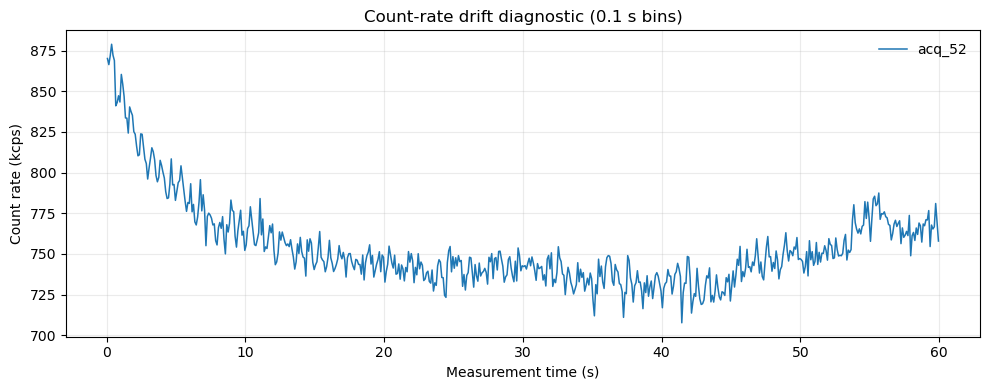

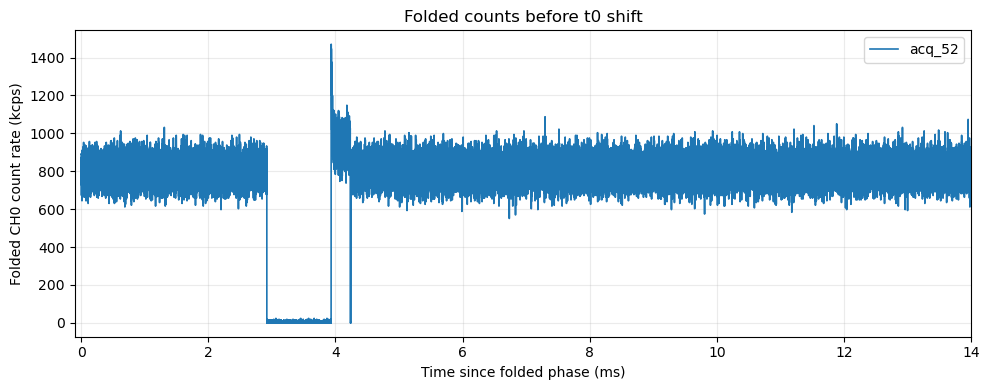

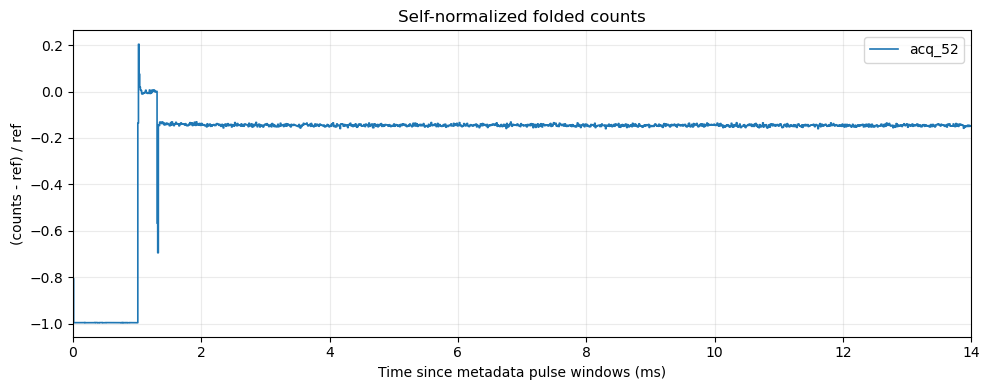

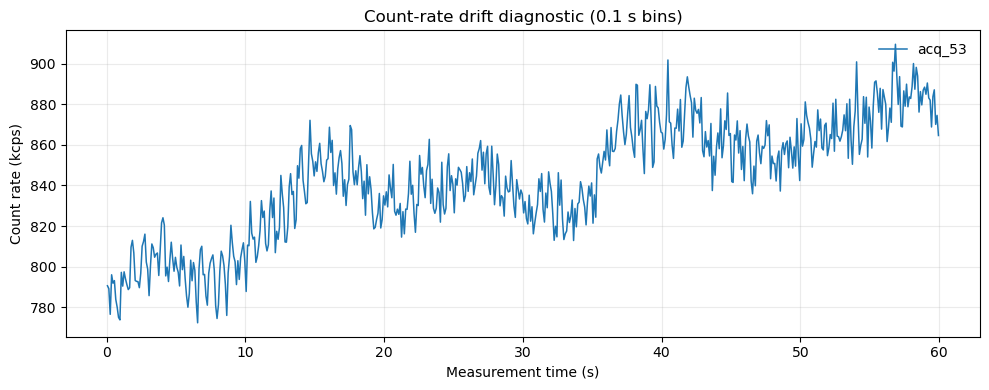

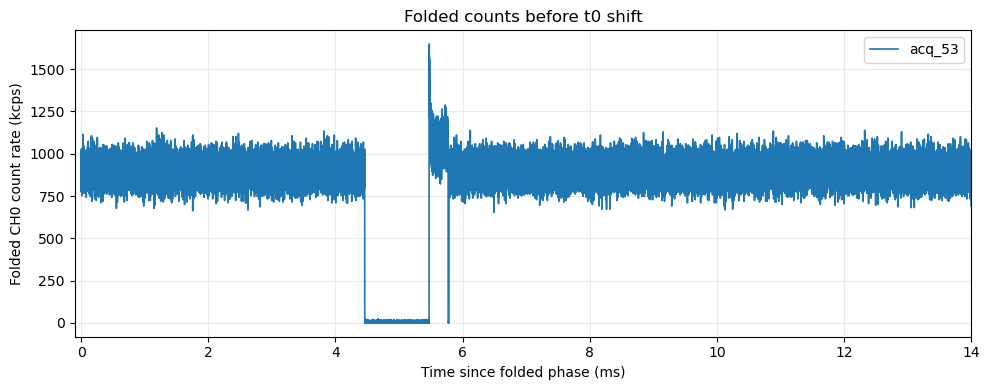

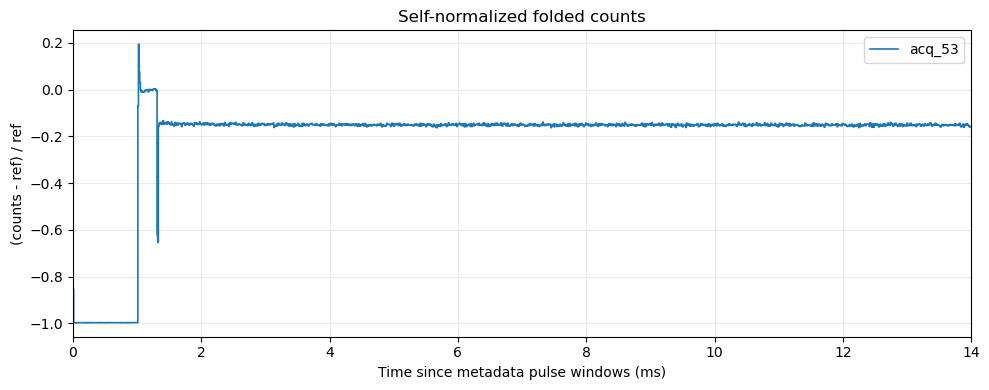

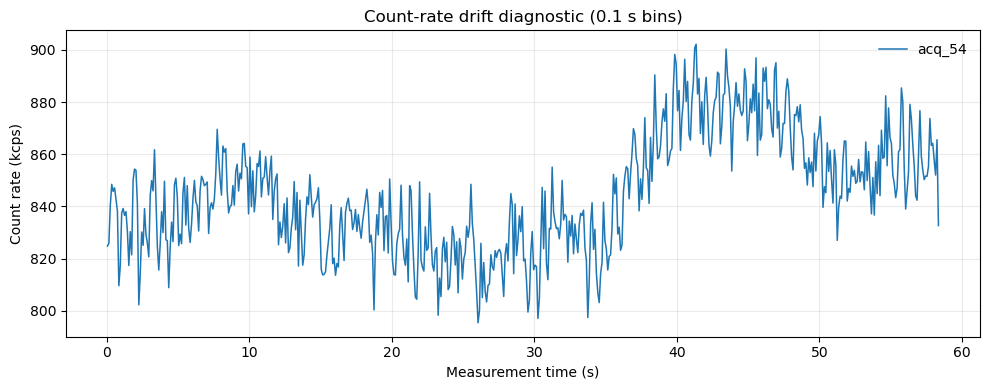

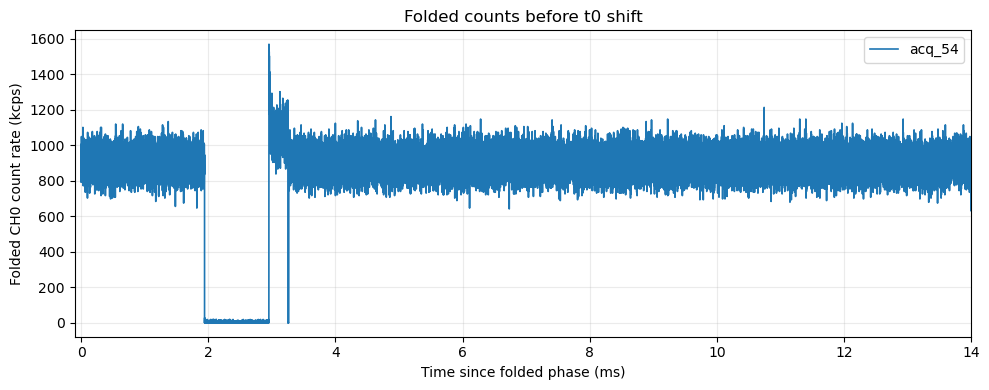

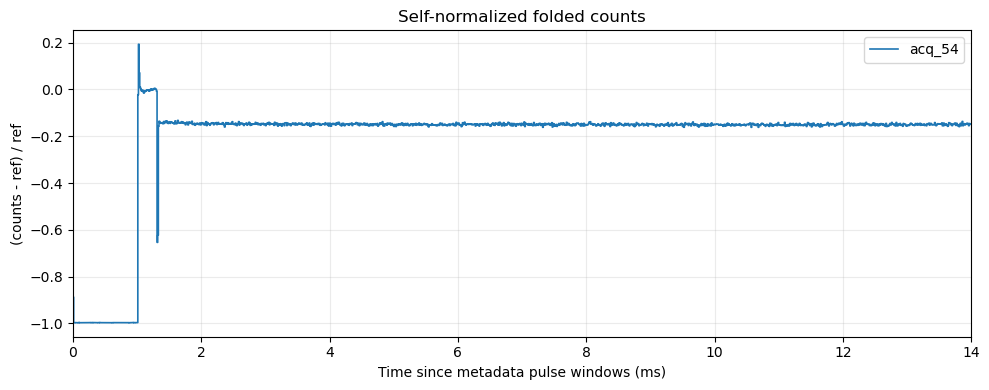

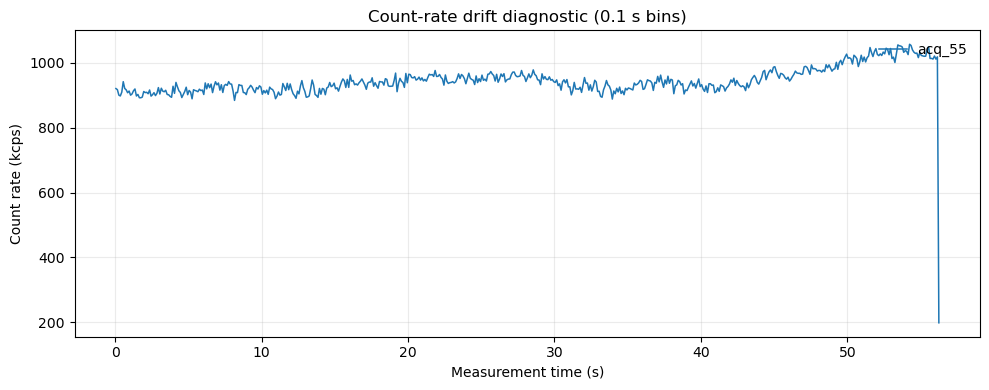

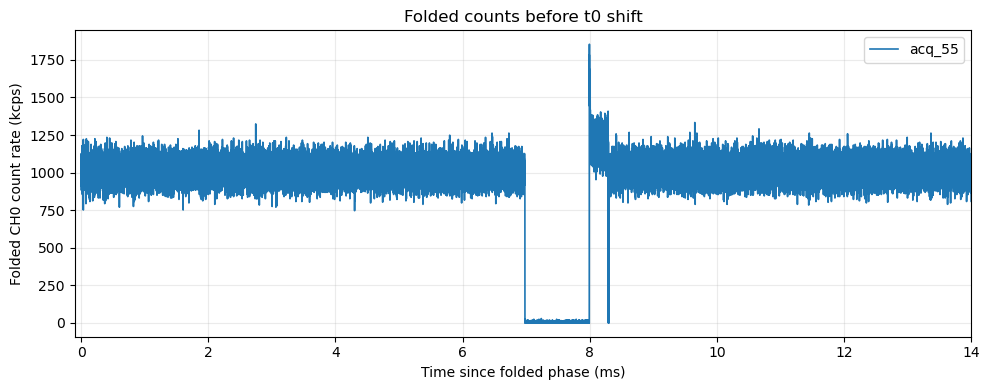

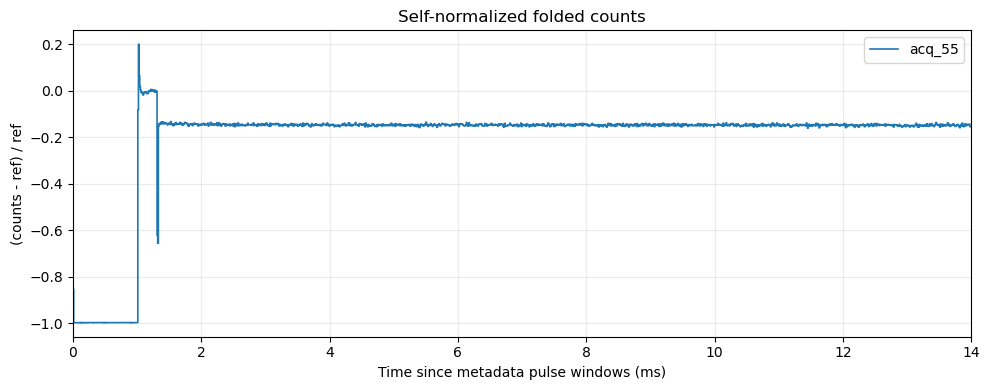

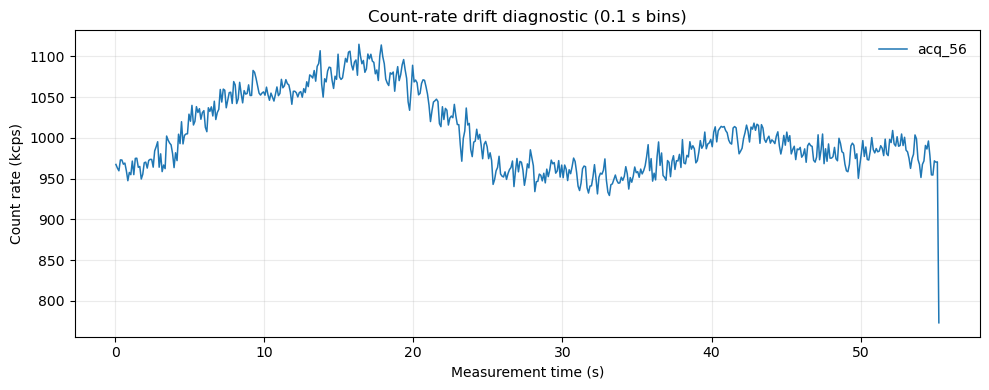

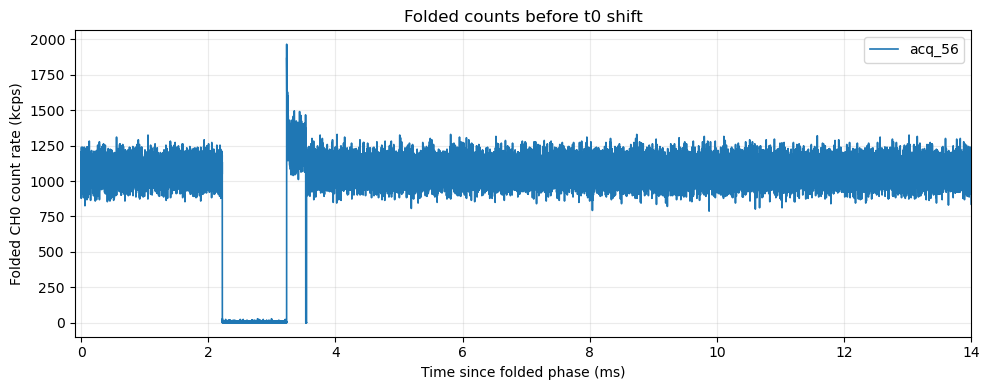

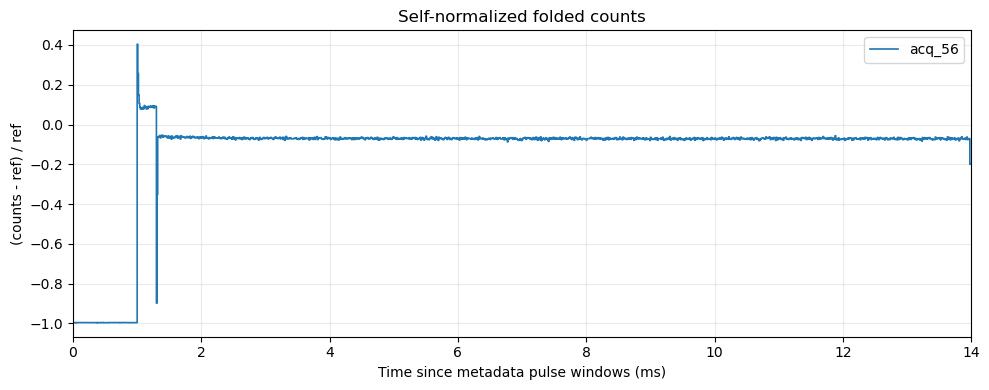

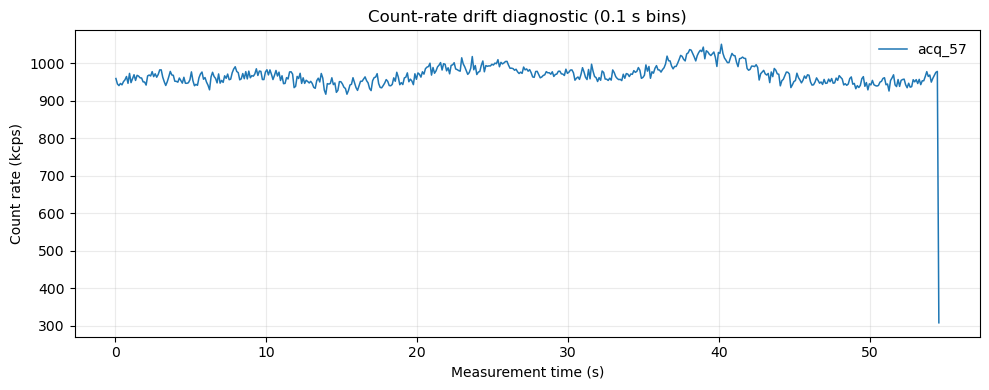

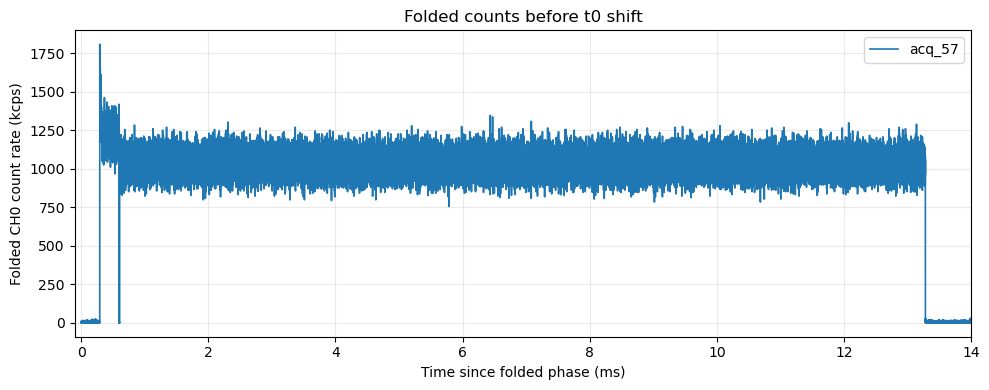

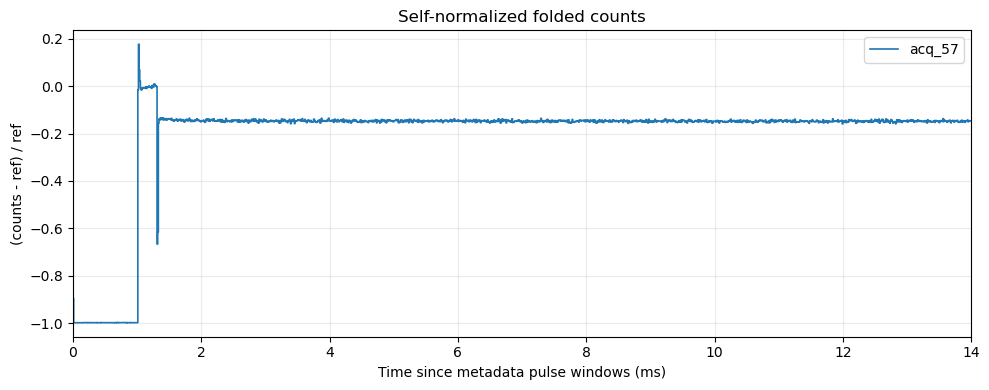

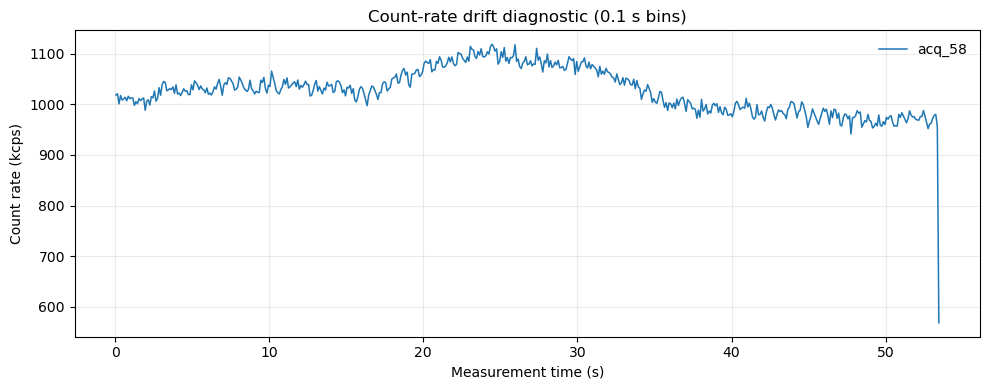

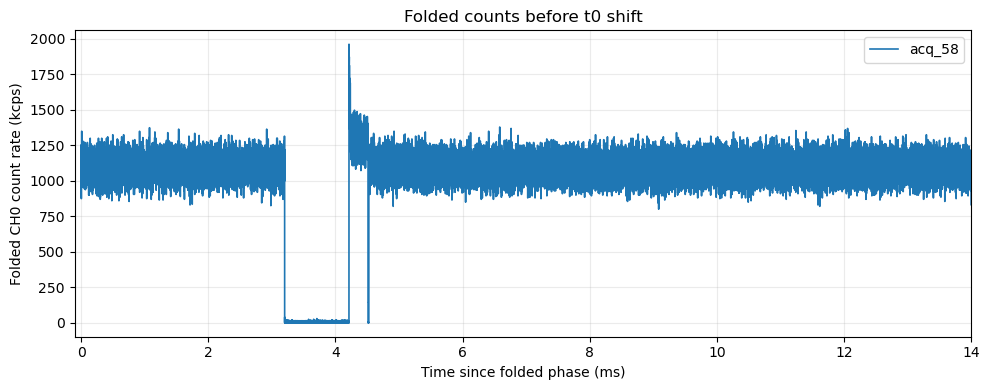

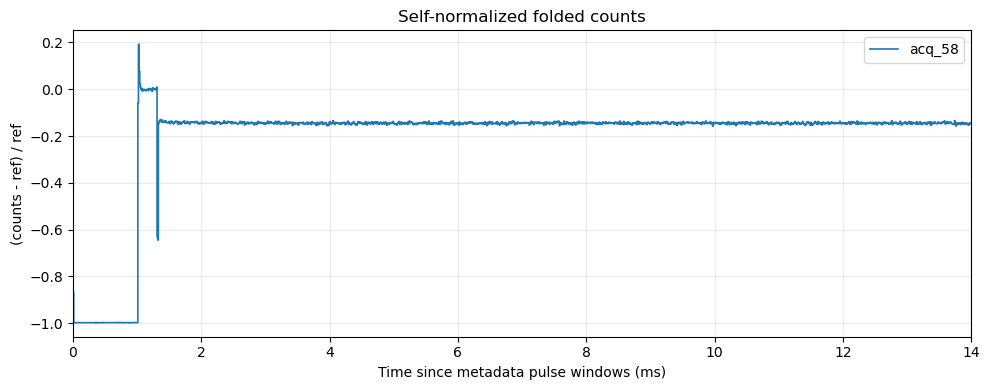

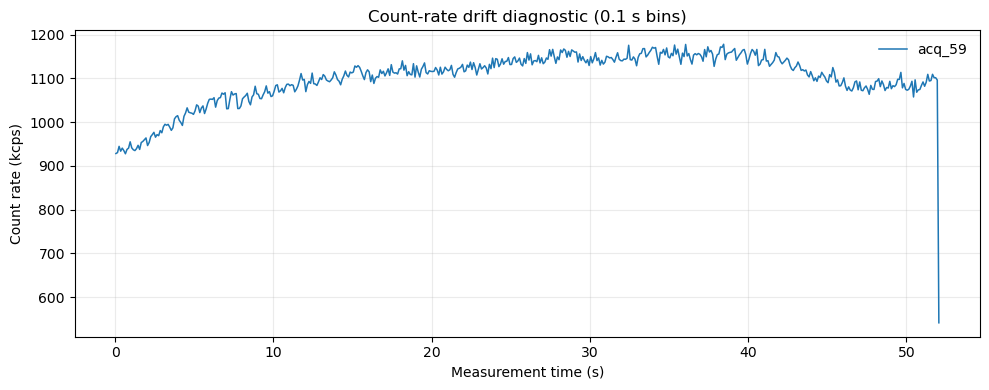

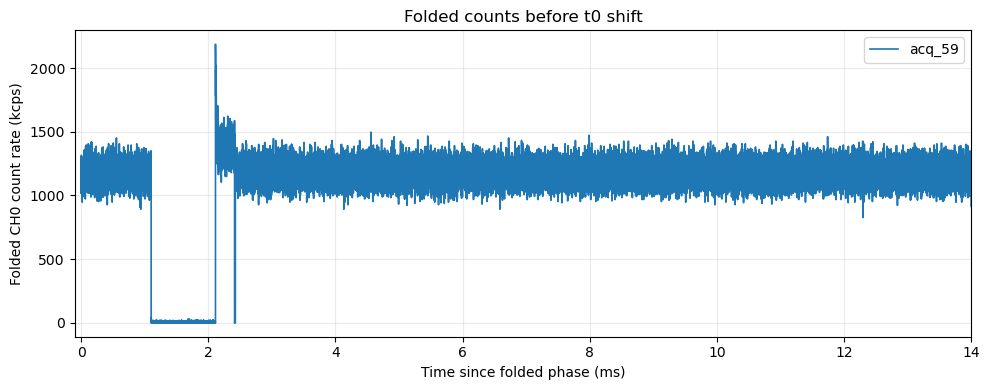

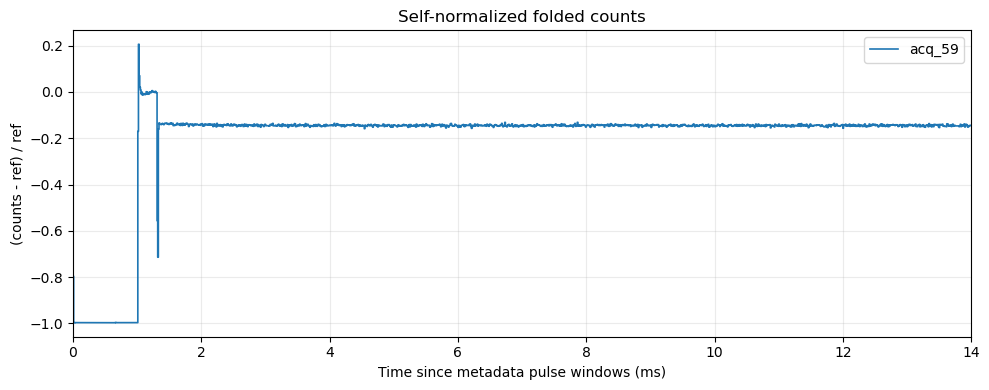

In [25]:
DATA_ROOT = Path(r"Q:\MoTe2_PP_local\20260710_Vmu_scan_X14_y36")


for i in range(60,68):
    
    try:
        results = analyze_new_timetrace(
            [i],
            data_root=DATA_ROOT,
            desired_count_rate_kcps=None,
            count_rate_bin_s=0.1,
            count_rate_channels=(0, 1),
            sync_tick_stride=100,
            raw_bin_us=0.05,
            raw_lims=[-.1, 14],
            normalized_bin_us= 10,
            normalized_lims=[0.0,14],
            ref_range=[1.2,1.3],
            t0_method="metadata_windows", 
            use_previous_reference=False, 
            unit="ms",
            force_recompute_count_rate=False,
            force_recompute_fold=False,
            wait_for_files=True,
            wait_poll_interval_s=10,
            wait_completion_margin_s=2,
            show_progress=True,
        )
        print(f"Analysis of acq_{i} successful.")
    except Exception as exc:
        print(f"Analysis of acq_{i} failed: {exc}")
    finally:
        # plt.close("all") ######## CAREFUL, WHEN ANALYZING MANY MEASUREMENTS, THIS NEEDS TO HAPPEN FOR STABILITY
        if "results" in locals():
            del results
        gc.collect() 

